# 05 Model Scientific Interest

Canonical modeling notebook for yearly scientific interest.
This notebook computes SI, ranks future high-interest pathogen-antibiotic pairs, and generates focused plots.
Set `ANTIBIOTIC_ANALYSIS_LEVEL` to `"antibiotic"` for individual antibiotics, or to a column in `assets/antibiotic_coarsening_lookup.csv` such as `"Class"`.


In [1]:
%load_ext autoreload
%autoreload 2


In [2]:
from pathlib import Path
import sys

from IPython.display import display

PROJECT_ROOT = Path.cwd().resolve()
if not (PROJECT_ROOT / "amr").exists():
    PROJECT_ROOT = PROJECT_ROOT.parent
if not (PROJECT_ROOT / "amr").exists():
    raise RuntimeError(f"Could not find repository root from {Path.cwd()}")
if str(PROJECT_ROOT) not in sys.path:
    sys.path.insert(0, str(PROJECT_ROOT))

from amr.pipelines.si import (
    DEFAULT_DRIVER_SUMMARY_COLUMNS,
    DEFAULT_DECREASING_SI_SUMMARY_COLUMNS,
    DEFAULT_SMOOTHED_SI_SHAPE_SUMMARY_COLUMNS,
    DEFAULT_INTERESTING_SUMMARY_COLUMNS,
    build_si_analysis_paths,
    build_si_driver_analysis,
    build_yearly_si_dataset,
    filter_model_inputs_by_average_amr_publications,
    load_yearly_si_inputs,
    prepare_antibiotic_analysis_level,
    print_si_dataset_summary,
    rank_future_high_interest_pairs,
    save_category_driver_plots,
    save_category_driver_pie_grid,
    save_interesting_si_plots,
    save_smoothed_si_screen_plots,
    select_existing_columns,
    summarize_smoothed_si_shapes,
    select_smoothed_si_shape_cases,
    select_decreasing_smoothed_si_trends,
    summarize_pair_publication_rates,
    summarize_pathogen_coverage,
)
from amr.pipeline_config import cfg, cfg_path, load_pipeline_config


## Configuration


In [3]:
PIPELINE_CONFIG = load_pipeline_config(project_root=PROJECT_ROOT)

OUTPUT_DIR = cfg_path(PIPELINE_CONFIG, "paths.output_dir", PROJECT_ROOT)
PARQUET_OUTPUT_DIR = cfg_path(PIPELINE_CONFIG, "paths.parquet_dir", PROJECT_ROOT)
PARQUET_OUTPUT_DIR.mkdir(parents=True, exist_ok=True)
DATA_DIR = PARQUET_OUTPUT_DIR

YEARLY_SCREENED_PATH = cfg_path(PIPELINE_CONFIG, "paths.yearly_screened", PROJECT_ROOT)
UNIFIED_DECISIONS_PATH = cfg_path(PIPELINE_CONFIG, "paths.unified_decisions", PROJECT_ROOT)
PATHOGEN_BG_PATH = cfg_path(PIPELINE_CONFIG, "paths.pathogen_background", PROJECT_ROOT)
ANTIBIOTIC_BG_PATH = cfg_path(PIPELINE_CONFIG, "paths.antibiotic_background", PROJECT_ROOT)
ANTIBIOTIC_COARSENING_PATH = cfg_path(PIPELINE_CONFIG, "paths.antibiotic_coarsening", PROJECT_ROOT)
DRIVER_CATEGORY_COARSENING_PATH = cfg_path(PIPELINE_CONFIG, "paths.driver_category_coarsening", PROJECT_ROOT)

# Analysis level controls antibiotic grouping for all SI model inputs and outputs.
ANTIBIOTIC_ANALYSIS_LEVEL = cfg(PIPELINE_CONFIG, "si.antibiotic_analysis_level")
SI_PATHS = build_si_analysis_paths(PROJECT_ROOT, ANTIBIOTIC_ANALYSIS_LEVEL)
YEARLY_SI_PATH = SI_PATHS["yearly_si"]
RANK_OUTPUT_PATH = SI_PATHS["rank_output"]
INTERESTING_OUTPUT_PATH = SI_PATHS["interesting_output"]
DRIVER_OUTPUT_PATH = SI_PATHS["driver_output"]
INTERESTING_PLOT_DIR = SI_PATHS["interesting_plot_dir"]
DRIVER_PLOT_DIR = SI_PATHS["driver_plot_dir"]
DECREASING_SI_OUTPUT_PATH = PARQUET_OUTPUT_DIR / "decreasing_smoothed_si_trends.parquet"
CONVEX_SI_OUTPUT_PATH = PARQUET_OUTPUT_DIR / "convex_u_shaped_smoothed_si_trends.parquet"
CONCAVE_SI_OUTPUT_PATH = PARQUET_OUTPUT_DIR / "concave_inverted_u_smoothed_si_trends.parquet"
DECREASING_SI_PLOT_DIR = OUTPUT_DIR / "figures" / "decreasing_smoothed_si_plots"
CONVEX_SI_PLOT_DIR = OUTPUT_DIR / "figures" / "convex_u_shaped_smoothed_si_plots"
CONCAVE_SI_PLOT_DIR = OUTPUT_DIR / "figures" / "concave_inverted_u_smoothed_si_plots"

# Fit/rank window controls.
FIT_START_YEAR = cfg(PIPELINE_CONFIG, "si.fit_start_year")
FIT_END_YEAR = cfg(PIPELINE_CONFIG, "si.fit_end_year")
PUBLICATION_FILTER_END_YEAR = cfg(PIPELINE_CONFIG, "si.publication_filter_end_year")
CURVE_FIT_END_YEAR = cfg(PIPELINE_CONFIG, "si.curve_fit_end_year")
NUM_FUTURE_YEARS = cfg(PIPELINE_CONFIG, "si.num_future_years")
PLOT_END_YEAR = CURVE_FIT_END_YEAR + NUM_FUTURE_YEARS

# Pair filtering and interesting-pair ranking thresholds.
MIN_TOTAL_AMR_PUBLICATIONS = cfg(PIPELINE_CONFIG, "si.min_tot_amr_publications")
MIN_CURRENT_PREDICTED_COUNT = cfg(PIPELINE_CONFIG, "si.min_current_predicted_count")
MIN_FUTURE_PREDICTED_COUNT = cfg(PIPELINE_CONFIG, "si.min_future_predicted_count")
MIN_SI_CHANGE = cfg(PIPELINE_CONFIG, "si.min_si_change")
MIN_POST_FIT_OBSERVED_YEARS = cfg(PIPELINE_CONFIG, "si.min_post_fit_observed_years")
MAX_POST_FIT_SI_ABS_PCT_ERROR_MEAN = cfg(PIPELINE_CONFIG, "si.max_post_fit_si_abs_pct_error_mean")
MAX_SI_LOESS_RESIDUAL_VARIANCE_MEAN = cfg(PIPELINE_CONFIG, "si.max_si_loess_residual_variance_mean")
FALLBACK_TOP_N = cfg(PIPELINE_CONFIG, "si.fallback_top_n")

# Driver plots and display controls.
CATEGORY_INCLUDE_DECISIONS = tuple(cfg(PIPELINE_CONFIG, "si.category_include_decisions"))
DRIVER_CATEGORY_LEVEL = cfg(PIPELINE_CONFIG, "si.driver_category_level")
DRIVER_LOOKBACK_YEARS = cfg(PIPELINE_CONFIG, "si.driver_lookback_years")
MAX_DRIVER_PLOTS = cfg(PIPELINE_CONFIG, "si.max_driver_plots")
DRIVER_PIE_GRID_COLUMNS = cfg(PIPELINE_CONFIG, "si.driver_pie_grid_columns")
MAX_INTERESTING_PLOTS = cfg(PIPELINE_CONFIG, "si.max_interesting_plots")
FIGURE_FORMAT = cfg(PIPELINE_CONFIG, "si.figure_format")
DISPLAY_PLOTS = cfg(PIPELINE_CONFIG, "si.display_plots")
MAX_DISPLAY_PLOTS = cfg(PIPELINE_CONFIG, "si.max_display_plots")
FILL_MISSING_AMR_COUNTS_WITH_ZERO = cfg(PIPELINE_CONFIG, "si.fill_missing_amr_counts_with_zero")
LOESS_FRAC = cfg(PIPELINE_CONFIG, "si.loess_frac")
LOESS_DEGREE = cfg(PIPELINE_CONFIG, "si.loess_degree")
TAIL_DAMPING_YEARS = cfg(PIPELINE_CONFIG, "si.tail_damping_years")
SHAPE_SCREEN_PLOT_COUNT = cfg(PIPELINE_CONFIG, "si.shape_screen_plot_count")


## Load Canonical Inputs


In [4]:
yearly_screened_df, pathogen_bg_df, antibiotic_bg_df, unified_decisions_df = load_yearly_si_inputs(
    yearly_screened_path=YEARLY_SCREENED_PATH,
    pathogen_background_path=PATHOGEN_BG_PATH,
    antibiotic_background_path=ANTIBIOTIC_BG_PATH,
    unified_decisions_path=UNIFIED_DECISIONS_PATH,
)


yearly_screened rows: 23,355
yearly_screened unique pathogens: 201
yearly_screened unique antibiotics: 196
yearly_screened year range: 2000 - 2026
pathogen bg rows: 10,854
antibiotic bg rows: 5,346
unified decision rows available for driver analysis: 186,724


## Prepare Antibiotic Analysis Level

This step optionally aggregates from individual antibiotics to a selected coarsening column before SI modeling.


In [5]:
yearly_screened_model_df, antibiotic_bg_model_df, unified_decisions_model_df, analysis_summary = prepare_antibiotic_analysis_level(
    yearly_screened_df=yearly_screened_df,
    antibiotic_background_df=antibiotic_bg_df,
    unified_decisions_df=unified_decisions_df,
    coarsening_path=ANTIBIOTIC_COARSENING_PATH,
    analysis_level=ANTIBIOTIC_ANALYSIS_LEVEL,
)

yearly_screened_model_df.head(10)


Antibiotic analysis level: individual antibiotic.
model yearly rows: 23,355
model pathogen-antibiotic rows: 4,328
model antibiotic values: 196
model antibiotic background rows: 5,346
model unified decision rows: 186,724


,pathogen,antibiotic,year,pmids,count
0,Achromobacter denitrificans,Amikacin,2026,[42414032],1
1,Achromobacter denitrificans,Aztreonam,2021,[33766786],1
2,Achromobacter denitrificans,Cefiderocol,2022,[35029278],1
3,Achromobacter denitrificans,Cefiderocol,2026,[41586494],1
4,Achromobacter denitrificans,Ceftazidime,2022,[35029278],1
5,Achromobacter denitrificans,Ceftazidime,2026,[41586494],1
6,Achromobacter denitrificans,Ceftazidime/avibactam,2026,[41586494],1
7,Achromobacter denitrificans,Ciprofloxacin,2013,[22944724],1
8,Achromobacter denitrificans,Ciprofloxacin,2021,[33766786],1
9,Achromobacter denitrificans,Ciprofloxacin,2022,[35029278],1


## Build Yearly SI Dataset


## Filter Low-Volume Pairs

Keep only pathogen-antibiotic pairs with enough screened AMR publications on average across the fitting window. The average includes years with zero publications.


In [6]:
yearly_screened_model_unfiltered_df = yearly_screened_model_df.copy()

yearly_screened_model_df, unified_decisions_model_df, pair_publication_rates = filter_model_inputs_by_average_amr_publications(
    yearly_screened_model_df=yearly_screened_model_df,
    unified_decisions_model_df=unified_decisions_model_df,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    publication_filter_end_year=PUBLICATION_FILTER_END_YEAR,
    min_total_amr_publications=MIN_TOTAL_AMR_PUBLICATIONS,
)

pathogen_filter_summary_df = summarize_pathogen_coverage(
    source_df=yearly_screened_model_unfiltered_df,
    modeled_df=yearly_screened_model_df,
    source_label="model input before publication filter",
    modeled_label="model input after publication filter",
)

display(pathogen_filter_summary_df.query("status != 'present_in_both'"))
summarize_pair_publication_rates(pair_publication_rates, head=30)


AMR publication filter: kept 187 / 4,328 pairs with >= 50 total publications from 2000 to 2025.
model input before publication filter pathogens: 201
model input after publication filter pathogens: 26
Pathogens present in model input before publication filter but absent from model input after publication filter: 175
Achromobacter denitrificans, Achromobacter xylosoxidans, Acinetobacter calcoaceticus, Actinotignum schaalii, Aeromonas caviae, Aeromonas hydrophila, Aeromonas salmonicida, Aeromonas sobria, Aeromonas veronii, Aggregatibacter actinomycetemcomitans, Bacillus anthracis, Bacillus cereus, Bartonella bacilliformis, Bartonella quintana, Bordetella bronchiseptica, Bordetella hinzii, Bordetella parapertussis, Bordetella pertussis, Borrelia burgdorferi, Brucella intermedia, Brucella melitensis, Burkholderia cenocepacia, Burkholderia cepacia, Burkholderia multivorans, Burkholderia pseudomallei, Campylobacter fetus, Chlamydia pneumoniae, Chlamydia psittaci, Chlamydia trachomatis, Chromo

,pathogen,source_rows,source_publications,source_pairs,modeled_rows,modeled_publications,modeled_pairs,in_source,in_modeled,status
0,Achromobacter denitrificans,20,21,12,0.0,0.0,0.0,True,False,missing_from_modeled
1,Achromobacter xylosoxidans,44,50,24,0.0,0.0,0.0,True,False,missing_from_modeled
2,Acinetobacter calcoaceticus,35,35,19,0.0,0.0,0.0,True,False,missing_from_modeled
3,Actinotignum schaalii,11,11,11,0.0,0.0,0.0,True,False,missing_from_modeled
4,Aeromonas caviae,32,35,22,0.0,0.0,0.0,True,False,missing_from_modeled
...,...,...,...,...,...,...,...,...,...,...
170,Vibrio mimicus,1,1,1,0.0,0.0,0.0,True,False,missing_from_modeled
171,Vibrio vulnificus,28,28,16,0.0,0.0,0.0,True,False,missing_from_modeled
172,Yersinia enterocolitica,251,136,50,0.0,0.0,0.0,True,False,missing_from_modeled
173,Yersinia pestis,19,10,9,0.0,0.0,0.0,True,False,missing_from_modeled


,pathogen,antibiotic,fit_window_amr_publications,avg_amr_publications_per_year
3217,Staphylococcus aureus,Meticillin,3683,141.653846
1347,Escherichia coli,Ampicillin,1180,45.384615
3272,Staphylococcus aureus,Vancomycin,897,34.500000
1498,Escherichia coli,Tetracycline,740,28.461538
1395,Escherichia coli,Ciprofloxacin,737,28.346154
1658,Helicobacter pylori,Clarithromycin,732,28.153846
1400,Escherichia coli,Colistin,585,22.500000
1673,Helicobacter pylori,Metronidazole,547,21.038462
3232,Staphylococcus aureus,Oxacillin,538,20.692308
3194,Staphylococcus aureus,Erythromycin,493,18.961538


In the next code cell, the notebook combines the screened yearly AMR counts with background publication counts to calculate a scientific-interest score for each pathogen-antibiotic-year. In simple terms, it estimates how much attention each pair is getting beyond what would be expected from general research activity alone, then saves those results for ranking and forecasting in later steps.


In [7]:
si_df, pooled_model, design_columns = build_yearly_si_dataset(
    yearly_screened_model_df,
    pathogen_bg_df,
    antibiotic_bg_model_df,
    output_path=YEARLY_SI_PATH,
)

print_si_dataset_summary(si_df)
si_pathogen_summary_df = summarize_pathogen_coverage(
    source_df=yearly_screened_model_df,
    modeled_df=si_df,
    source_label="filtered model input",
    modeled_label="yearly SI output",
)
display(si_pathogen_summary_df.query("status != 'present_in_both'"))
si_df.head(10)


SI rows: 4,605
SI pairs: 187
SI pathogens: 26
filtered model input pathogens: 26
yearly SI output pathogens: 26


,pathogen,source_rows,source_publications,source_pairs,modeled_rows,modeled_publications,modeled_pairs,in_source,in_modeled,status


,pathogen,antibiotic,year,pmids,count,bg_pathogen_n,bg_antibiotic_n,log_count,log_bg_pathogen_n,log_bg_antibiotic_n,expected_log_count_global,expected_count_global,SI
0,Acinetobacter baumannii,Amikacin,2003,"[12872781, 14748260]",2,80,183,0.477121,1.908485,2.264818,0.107199,0.279967,0.369923
1,Acinetobacter baumannii,Amikacin,2005,"[16103700, 16258323]",2,139,187,0.477121,2.146128,2.274158,0.219179,0.656451,0.257943
2,Acinetobacter baumannii,Amikacin,2006,"[16597632, 16776825]",2,176,194,0.477121,2.247973,2.290035,0.274084,0.879682,0.203037
3,Acinetobacter baumannii,Amikacin,2008,"[18261233, 18792817]",2,247,228,0.477121,2.394452,2.359835,0.380405,1.401072,0.096716
4,Acinetobacter baumannii,Amikacin,2009,[19795613],1,287,256,0.301030,2.459392,2.409933,0.438696,1.745971,-0.137666
5,Acinetobacter baumannii,Amikacin,2010,"[20107089, 20194701, 20499531, 20921306, 21137...",5,342,265,0.778151,2.535294,2.424882,0.481430,2.029913,0.296721
6,Acinetobacter baumannii,Amikacin,2011,[22016680],1,421,266,0.301030,2.625312,2.426511,0.522736,2.332241,-0.221706
7,Acinetobacter baumannii,Amikacin,2012,"[22104303, 22154196, 22461312, 22579564, 22808...",6,495,294,0.845098,2.695482,2.469822,0.579419,2.796807,0.265680
8,Acinetobacter baumannii,Amikacin,2013,"[23400749, 23435692, 23660097, 23668462, 23676...",9,511,368,1.000000,2.709270,2.567026,0.642211,3.387440,0.357789
9,Acinetobacter baumannii,Amikacin,2014,"[24235096, 24607428, 24653812, 25241558, 25336...",6,640,394,0.845098,2.806858,2.596597,0.703184,4.048748,0.141914


## Rank Reliable Future High-Interest Pairs


In [8]:
rank_df, interesting_df = rank_future_high_interest_pairs(
    si_df,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    min_current_predicted_count=MIN_CURRENT_PREDICTED_COUNT,
    min_future_predicted_count=MIN_FUTURE_PREDICTED_COUNT,
    min_si_change=MIN_SI_CHANGE,
    min_post_fit_observed_years=MIN_POST_FIT_OBSERVED_YEARS,
    max_post_fit_si_abs_pct_error_mean=MAX_POST_FIT_SI_ABS_PCT_ERROR_MEAN,
    max_si_loess_residual_variance_mean=MAX_SI_LOESS_RESIDUAL_VARIANCE_MEAN,
    fallback_top_n=FALLBACK_TOP_N,
    rank_output_path=RANK_OUTPUT_PATH,
    interesting_output_path=INTERESTING_OUTPUT_PATH,
    verbose=True,
)

select_existing_columns(
    interesting_df,
    DEFAULT_INTERESTING_SUMMARY_COLUMNS,
    head=30,
)


[1/187] ranking Acinetobacter baumannii vs Amikacin
[2/187] ranking Acinetobacter baumannii vs Ceftazidime
[3/187] ranking Acinetobacter baumannii vs Ciprofloxacin
[4/187] ranking Acinetobacter baumannii vs Colistin
[5/187] ranking Acinetobacter baumannii vs Gentamicin
[6/187] ranking Acinetobacter baumannii vs Meropenem
[7/187] ranking Acinetobacter baumannii vs Polymyxin-B
[8/187] ranking Acinetobacter baumannii vs Sulbactam
[9/187] ranking Acinetobacter baumannii vs Tetracycline
[10/187] ranking Acinetobacter baumannii vs Tigecycline
[11/187] ranking Bacteroides fragilis vs Metronidazole
[12/187] ranking Campylobacter coli vs Ciprofloxacin
[13/187] ranking Campylobacter coli vs Erythromycin
[14/187] ranking Campylobacter coli vs Tetracycline
[15/187] ranking Campylobacter jejuni vs Ampicillin
[16/187] ranking Campylobacter jejuni vs Ciprofloxacin
[17/187] ranking Campylobacter jejuni vs Erythromycin
[18/187] ranking Campylobacter jejuni vs Gentamicin
[19/187] ranking Campylobacter j

,pathogen,antibiotic,interest_score,si_change,current_predicted_count,future_predicted_count,si_loess_residual_variance_mean,post_fit_si_abs_pct_error_mean
0,Klebsiella pneumoniae,Piperacillin,0.176894,0.579483,11.918351,76.625423,0.052361,84.930432
1,Klebsiella pneumoniae,Ceftazidime,0.163137,0.272911,37.369986,124.998531,0.042228,3.171197
2,Klebsiella pneumoniae,Colistin,0.135476,0.221006,61.511490,138.764905,0.012901,8.987883
3,Staphylococcus aureus,Meticillin,0.105515,0.142190,404.202506,704.574883,0.003290,8.185918
4,Klebsiella pneumoniae,Meropenem,0.103229,0.173983,51.882282,134.218573,0.015636,11.651663
5,Staphylococcus aureus,Cefoxitin,0.099065,0.176509,32.843018,65.377829,0.013858,12.459514
6,Mycobacterium tuberculosis,Rifampicin,0.083682,0.166648,19.113887,34.132058,0.025706,21.241304
7,Escherichia coli,Tigecycline,0.079265,0.175155,15.036173,29.850453,0.017679,34.181510
8,Klebsiella pneumoniae,Ertapenem,0.065352,0.186279,13.658697,30.402344,0.015967,69.940959
9,Staphylococcus aureus,Ampicillin,0.062312,0.135598,31.892323,60.895033,0.017528,45.930369


## Explain Predicted SI Changes

This section uses the LLM category metadata from the unified abstract screen to describe which AMR paper types are driving the observed count curves behind the SI forecast. The analysis is descriptive: it explains category mix and recent changes, while the ranking itself remains based on the screened yearly AMR counts.


In [9]:
category_counts_df, interesting_with_drivers_df = build_si_driver_analysis(
    interesting_df=interesting_df,
    unified_decisions_df=unified_decisions_model_df,
    fit_end_year=FIT_END_YEAR,
    include_decisions=CATEGORY_INCLUDE_DECISIONS,
    lookback_years=DRIVER_LOOKBACK_YEARS,
    output_path=DRIVER_OUTPUT_PATH,
)

select_existing_columns(
    interesting_with_drivers_df,
    DEFAULT_DRIVER_SUMMARY_COLUMNS,
    head=30,
)


Saved SI driver explanations to /Users/f.costa/Code/Antimicrobial-Resistance/outputs/parquets/yearly_si_driver_explanations.parquet


,pathogen,antibiotic,interest_score,si_change,current_predicted_count,future_predicted_count,driver_recent_total,driver_count_change,driver_dominant_category,driver_fastest_growing_category,driver_weak_signal_share,driver_target_pair_supported_share
0,Klebsiella pneumoniae,Piperacillin,0.176894,0.579483,11.918351,76.625423,21,6,SURVEILLANCE,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,0.000000,1.0
1,Klebsiella pneumoniae,Ceftazidime,0.163137,0.272911,37.369986,124.998531,82,52,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,0.000000,1.0
2,Klebsiella pneumoniae,Colistin,0.135476,0.221006,61.511490,138.764905,166,109,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,SURVEILLANCE,0.000000,1.0
3,Staphylococcus aureus,Meticillin,0.105515,0.142190,404.202506,704.574883,1271,485,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,0.000787,1.0
4,Klebsiella pneumoniae,Meropenem,0.103229,0.173983,51.882282,134.218573,130,79,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,0.000000,1.0
5,Staphylococcus aureus,Cefoxitin,0.099065,0.176509,32.843018,65.377829,99,53,SURVEILLANCE,SURVEILLANCE,0.000000,1.0
6,Mycobacterium tuberculosis,Rifampicin,0.083682,0.166648,19.113887,34.132058,55,15,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,OTHER,0.000000,1.0
7,Escherichia coli,Tigecycline,0.079265,0.175155,15.036173,29.850453,46,31,SURVEILLANCE,SURVEILLANCE,0.000000,1.0
8,Klebsiella pneumoniae,Ertapenem,0.065352,0.186279,13.658697,30.402344,40,18,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,0.000000,1.0
9,Staphylococcus aureus,Ampicillin,0.062312,0.135598,31.892323,60.895033,94,44,SURVEILLANCE,MECHANISMS_OF_RESISTANCE_GENETICS_LAB_STUDIES,0.000000,1.0


## Plot Category Driver Curves


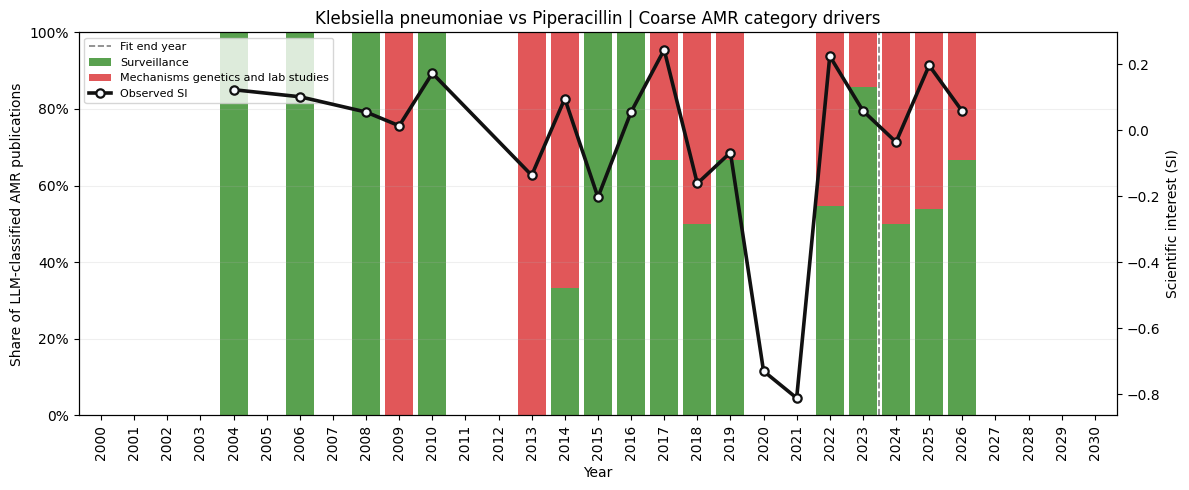

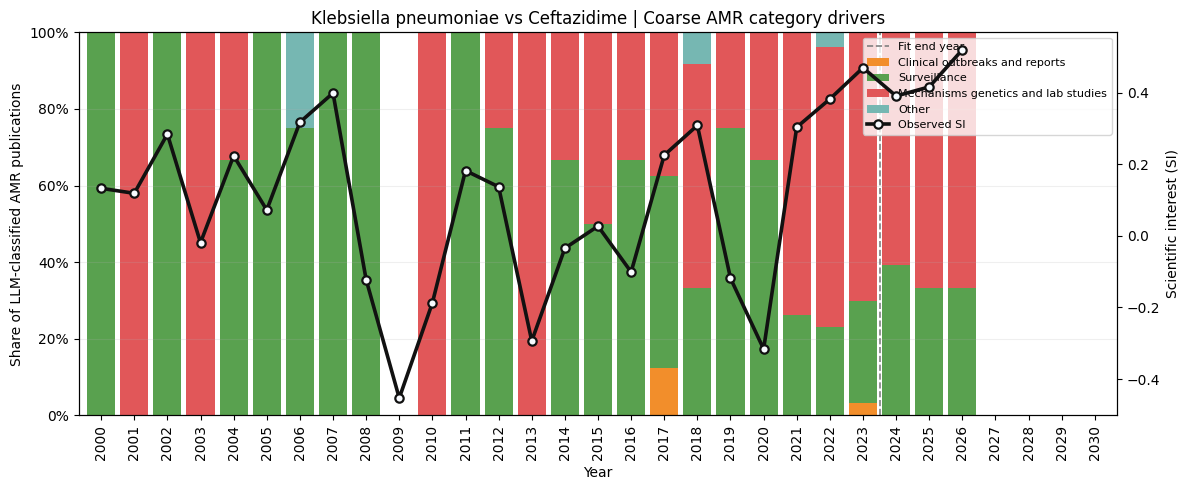

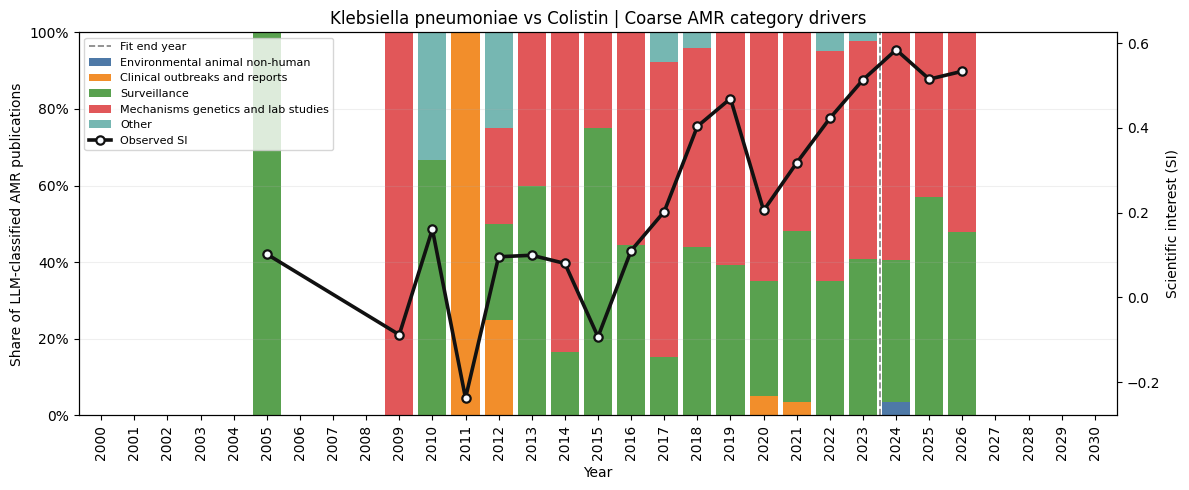

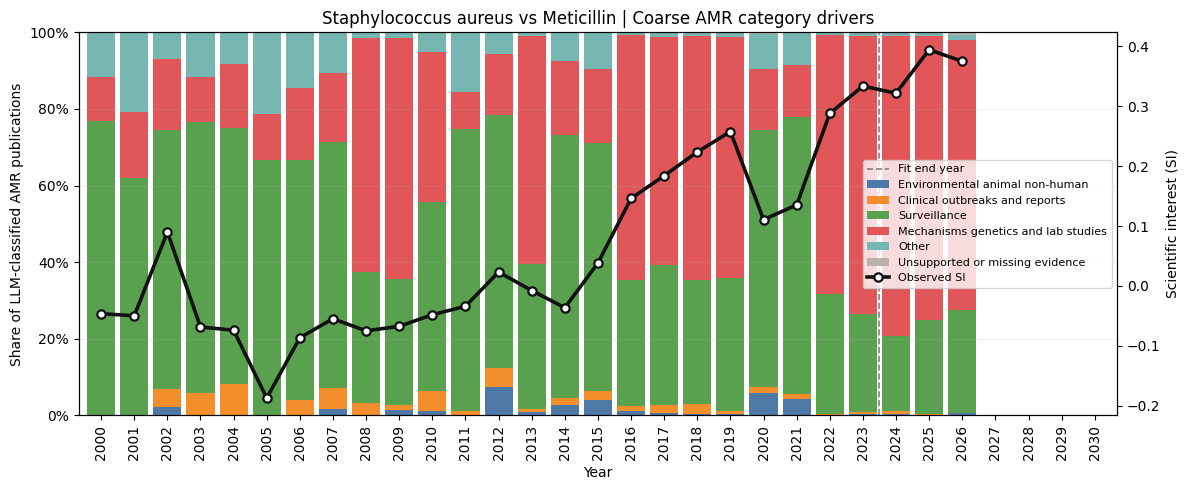

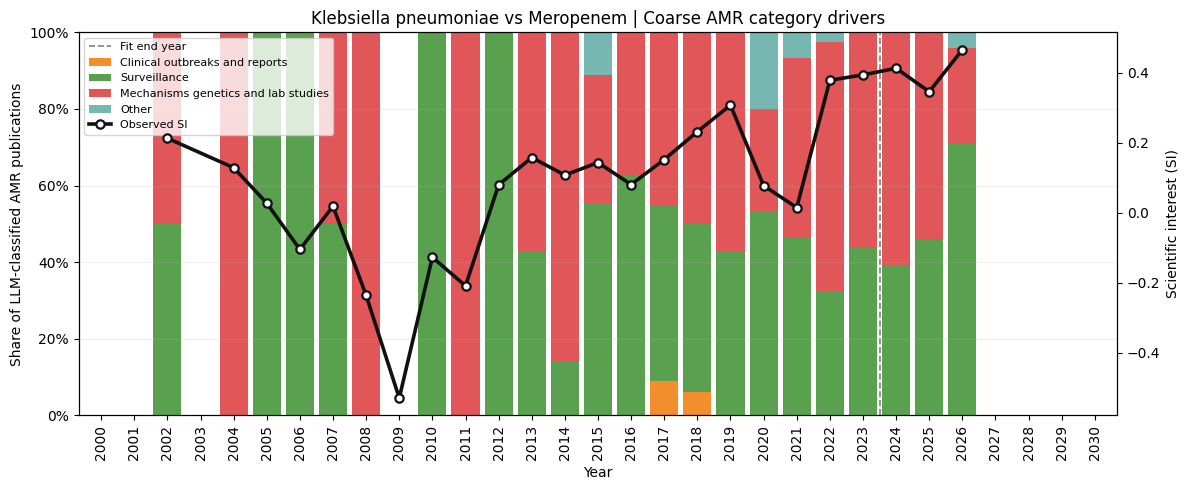

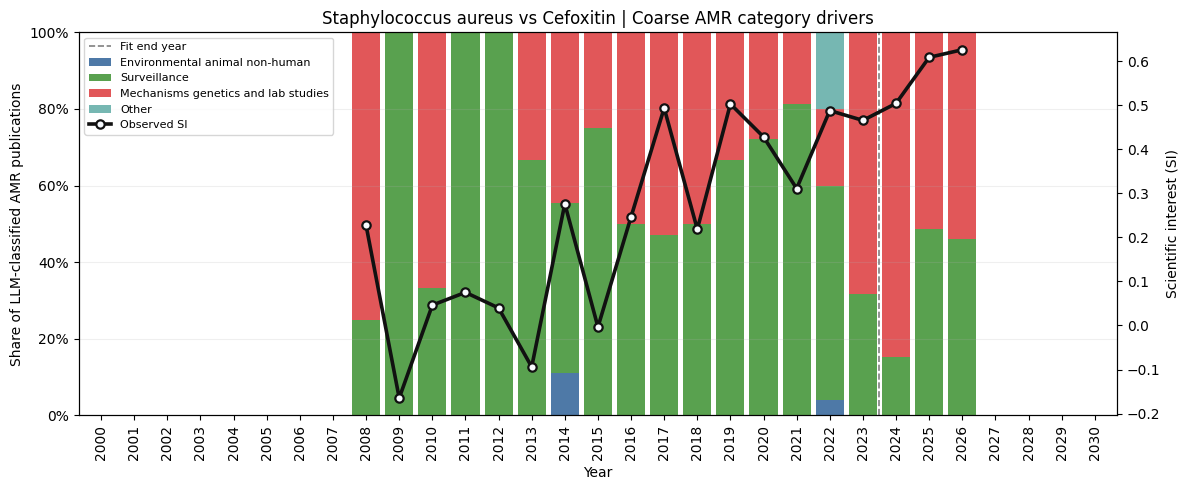

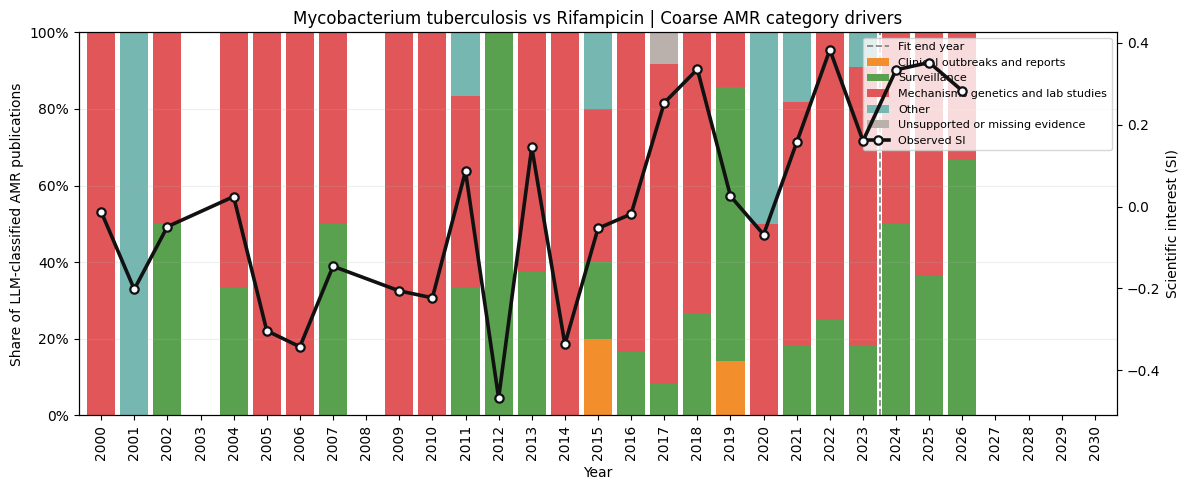

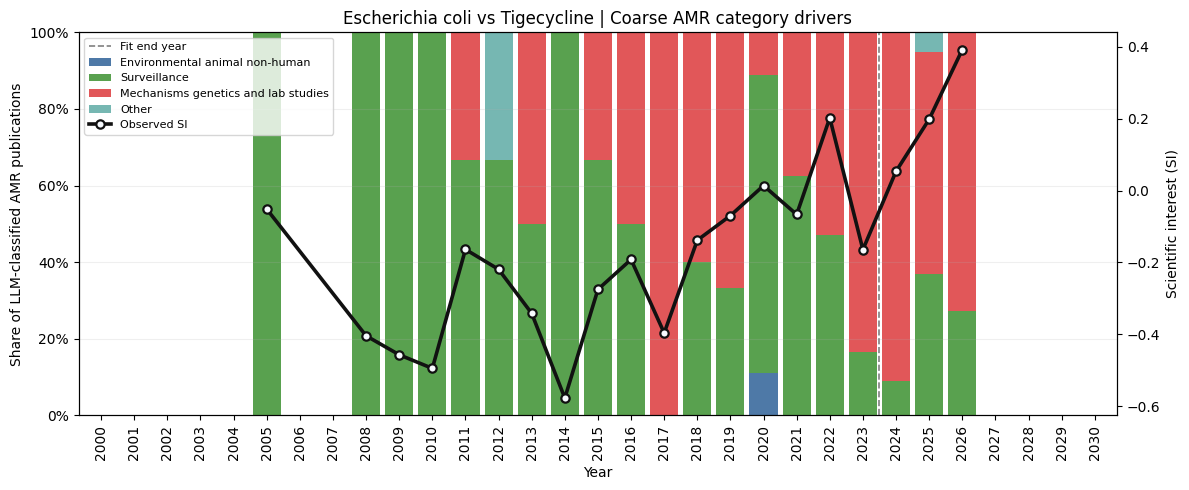

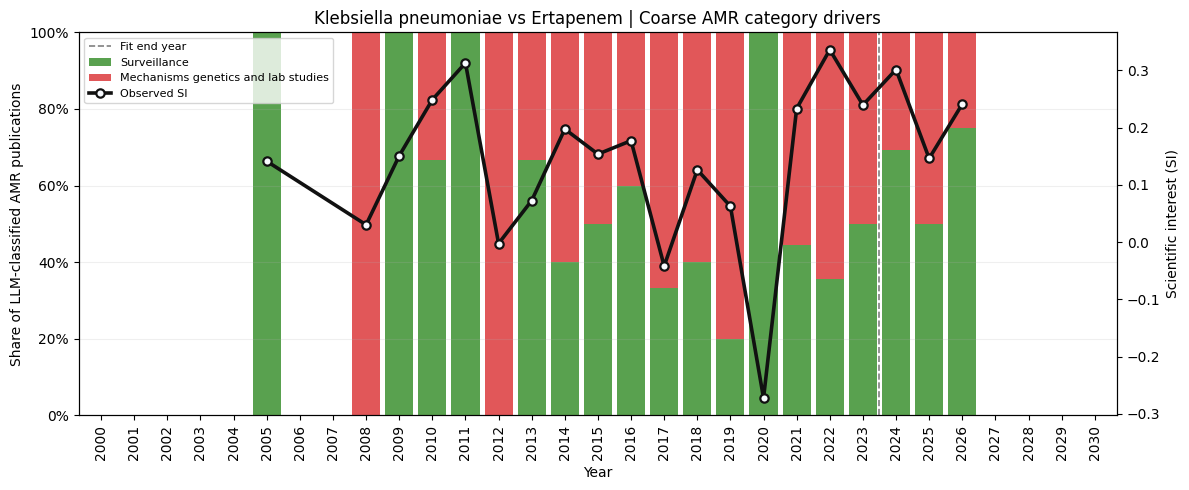

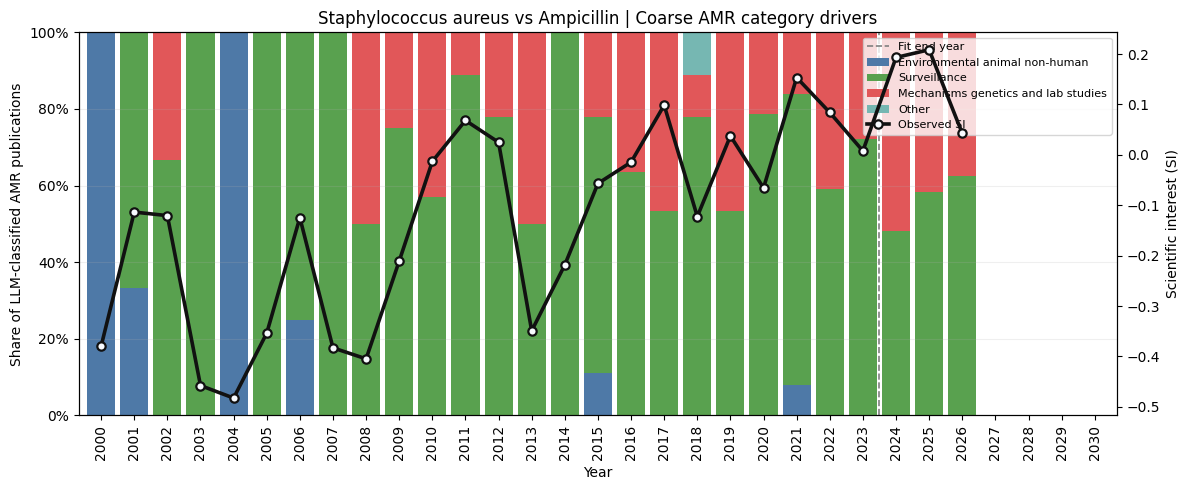

Saved 25 coarse category driver plots to /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/interesting_yearly_si_driver_plots
Displayed 10 category driver plots inline.
Saved all-year category driver pie grid for 36 pairs to /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/interesting_yearly_si_driver_plots/all_pairs_category_driver_pie_grid.pdf
Saved all-pair driver pie charts: 36 pairs -> /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/interesting_yearly_si_driver_plots/all_pairs_category_driver_pie_grid.pdf


In [10]:
saved_driver_plots = save_category_driver_plots(
    category_counts_df=category_counts_df,
    si_df=si_df,
    interesting_df=interesting_df,
    output_dir=DRIVER_PLOT_DIR,
    start_year=FIT_START_YEAR,
    end_year=PLOT_END_YEAR,
    fit_end_year=FIT_END_YEAR,
    max_plots=MAX_DRIVER_PLOTS,
    figure_format=FIGURE_FORMAT,
    driver_category_level=DRIVER_CATEGORY_LEVEL,
    category_coarsening_path=DRIVER_CATEGORY_COARSENING_PATH,
    display_plots=DISPLAY_PLOTS,
    max_display_plots=MAX_DISPLAY_PLOTS,
)

driver_pie_grid_path = DRIVER_PLOT_DIR / "all_pairs_category_driver_pie_grid.pdf"
saved_driver_pie_pairs = save_category_driver_pie_grid(
    category_counts_df=category_counts_df,
    si_df=si_df,
    interesting_df=interesting_df,
    output_path=driver_pie_grid_path,
    num_columns=DRIVER_PIE_GRID_COLUMNS,
    driver_category_level=DRIVER_CATEGORY_LEVEL,
    category_coarsening_path=DRIVER_CATEGORY_COARSENING_PATH,
    verbose=True,
)
print(f"Saved all-pair driver pie charts: {saved_driver_pie_pairs:,} pairs -> {driver_pie_grid_path}")


## Plot Top Interesting Pairs


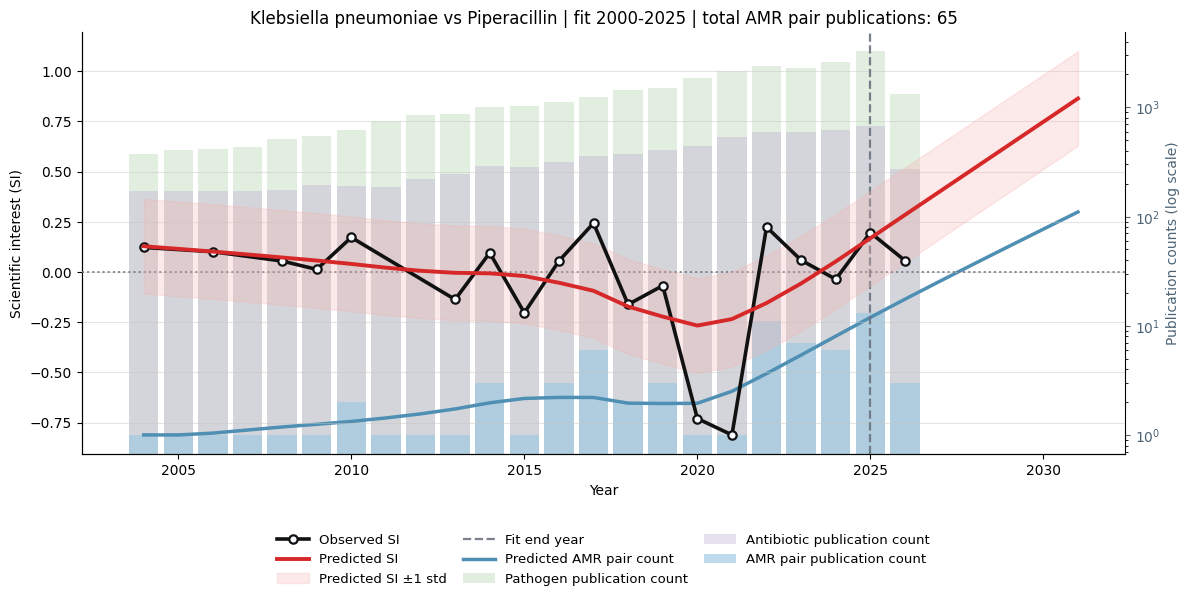

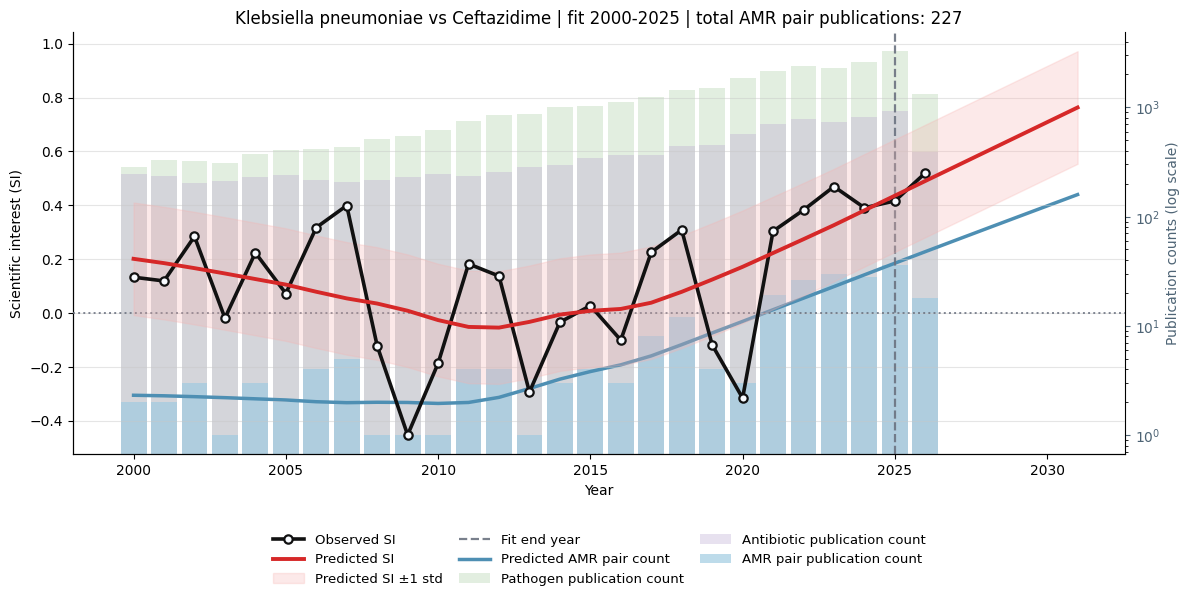

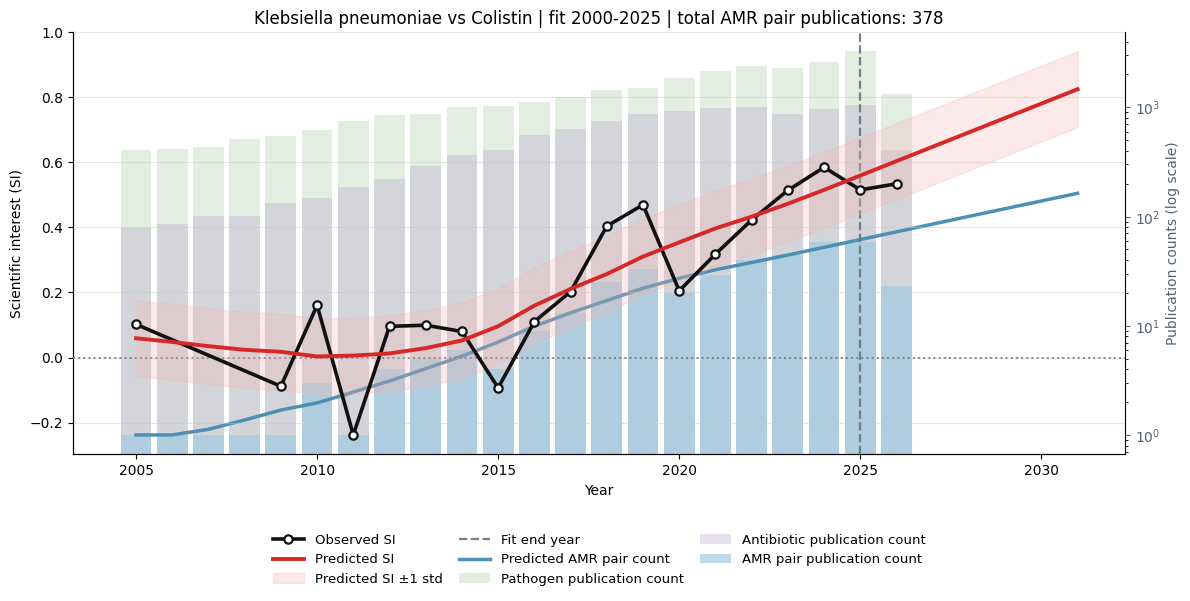

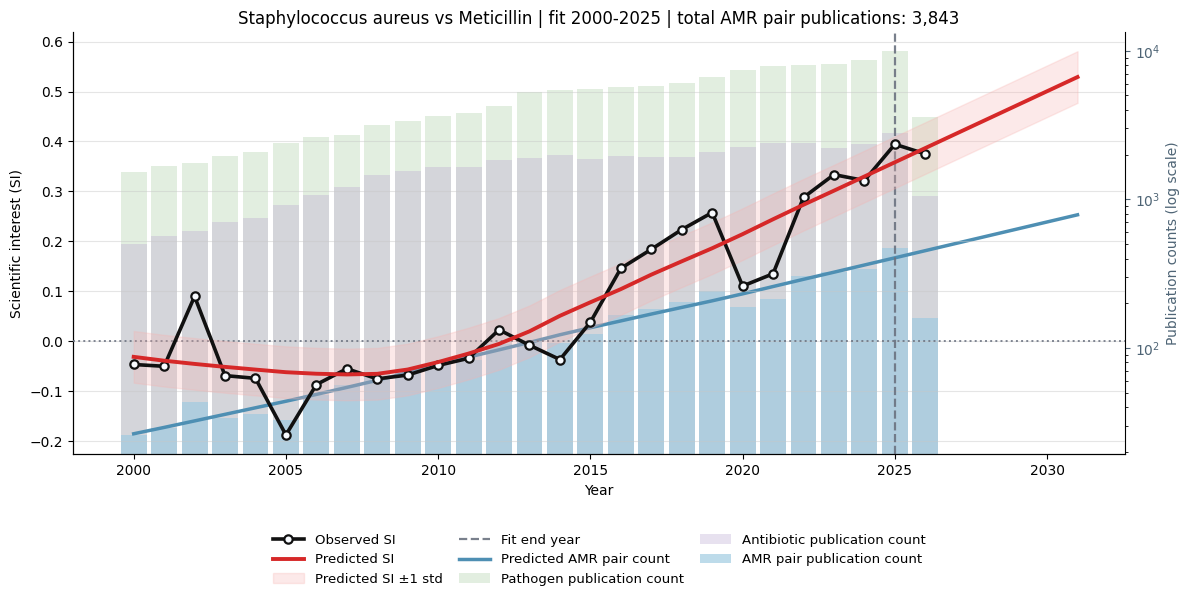

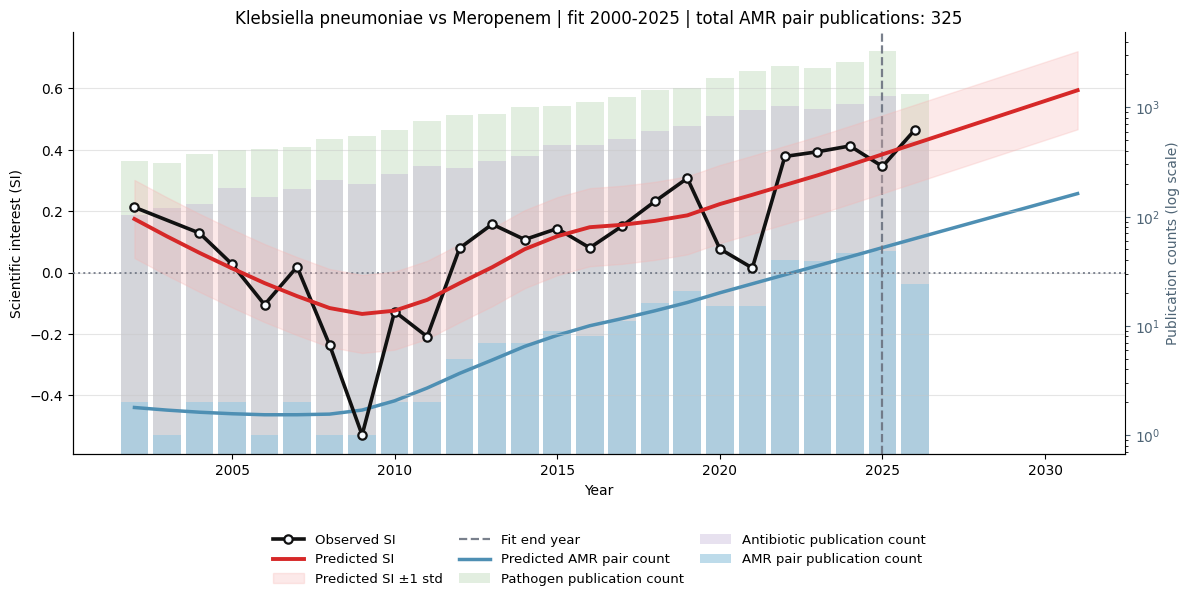

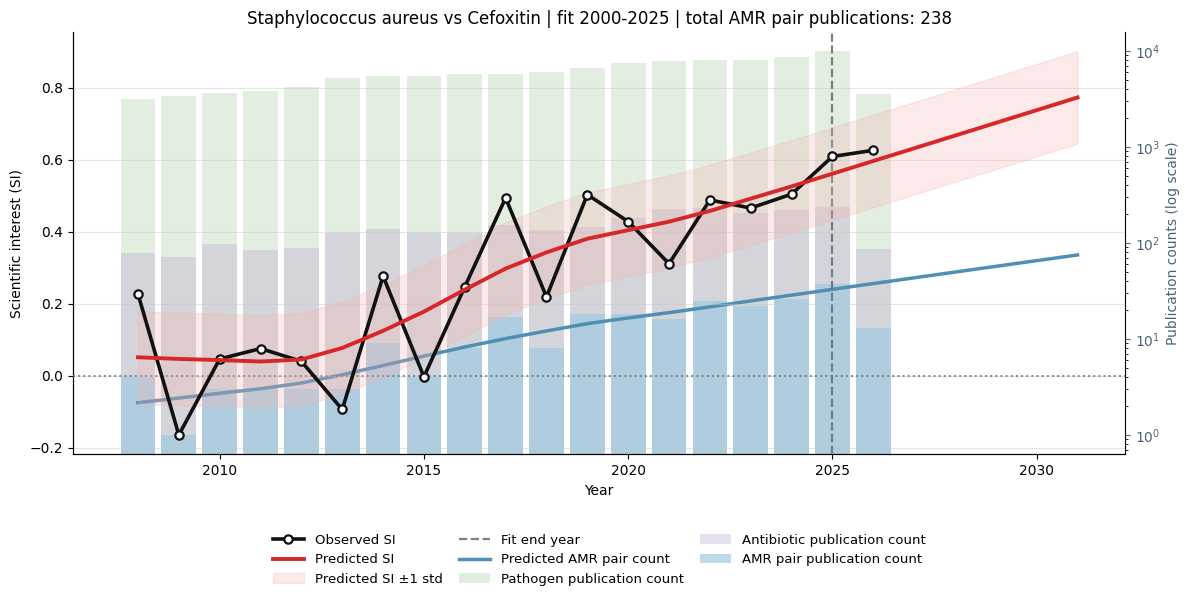

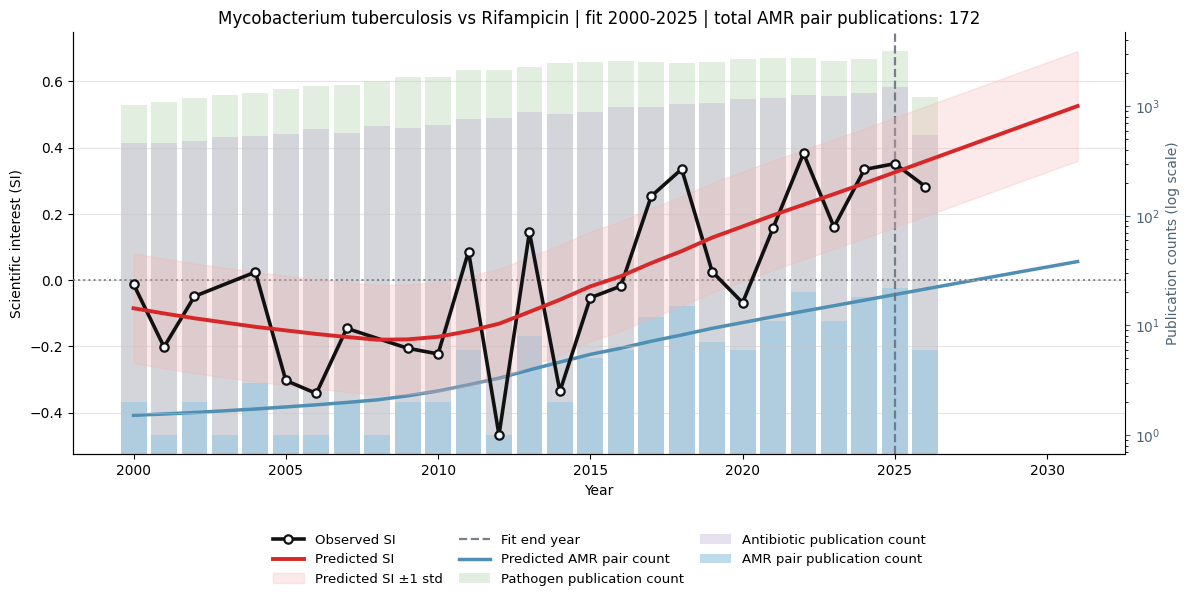

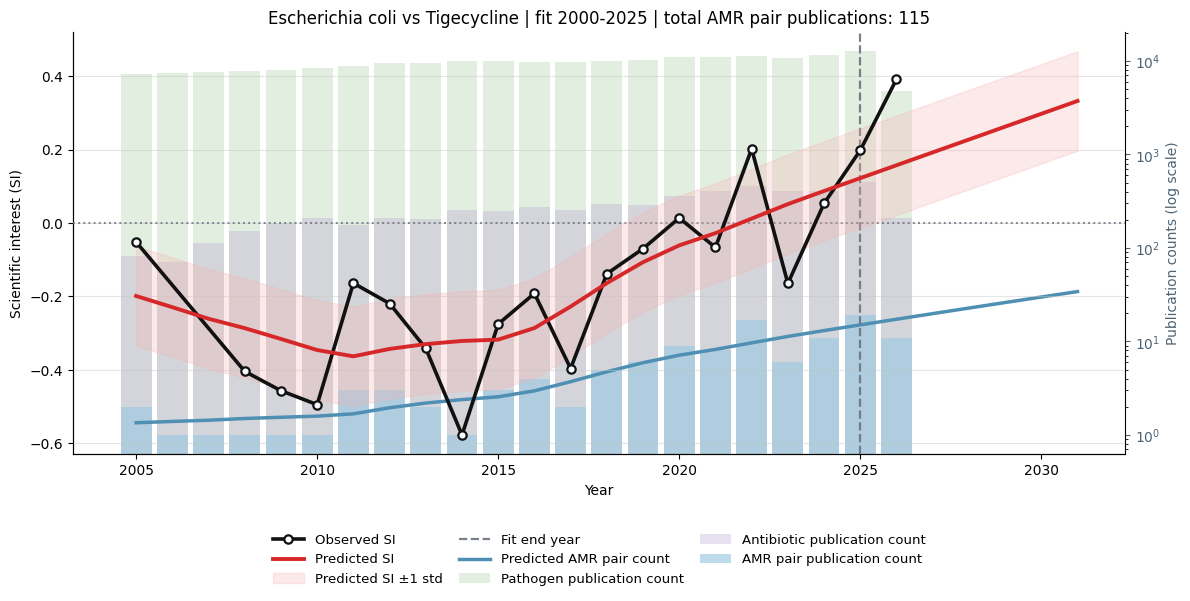

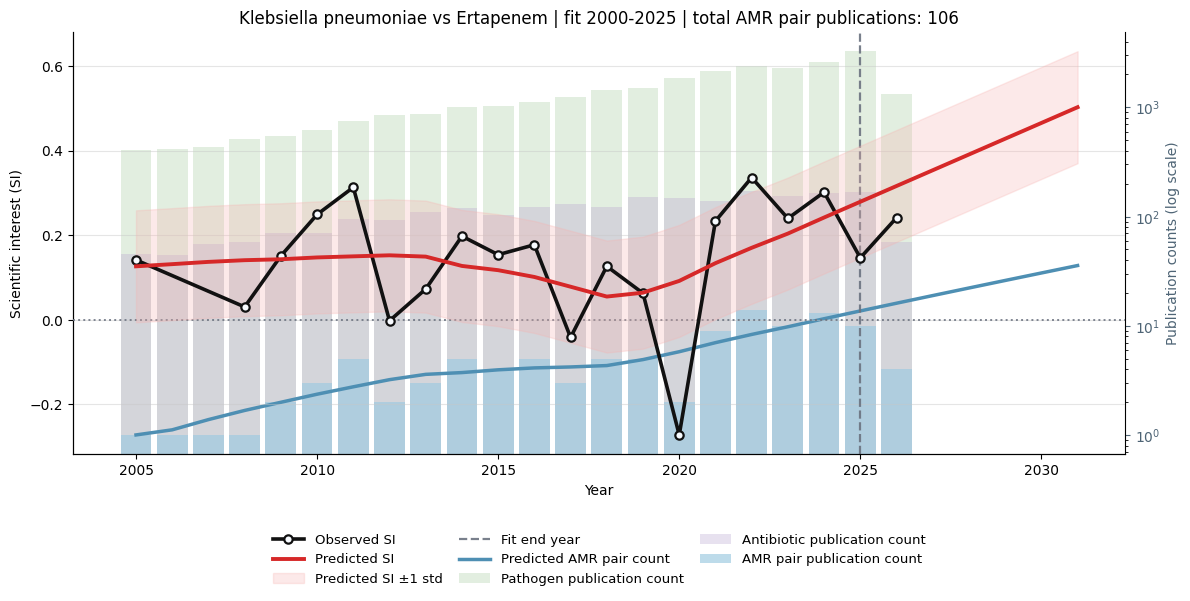

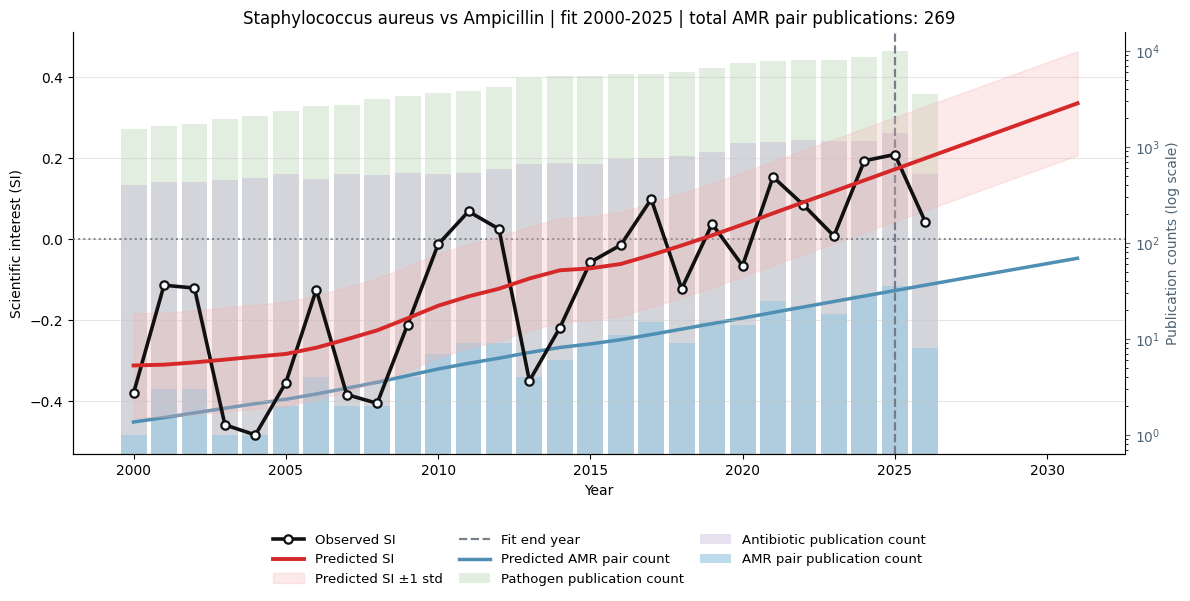

Saved 25 plots to /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/interesting_yearly_si_plots
Displayed 10 plots inline.


In [11]:
saved_interesting_plots = save_interesting_si_plots(
    si_df=si_df,
    interesting_df=interesting_df,
    output_dir=INTERESTING_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    fit_end_year=FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=MAX_INTERESTING_PLOTS,
    loess_frac=0.6,
    loess_degree=1,
    tail_damping_years=None,
    fill_missing_amr_counts_with_zero=FILL_MISSING_AMR_COUNTS_WITH_ZERO,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
    max_display_plots=MAX_DISPLAY_PLOTS,
)


## Additional SI Shape Screens


### Largest Decreasing Smoothed SI Trends


In [12]:
decreasing_smoothed_si_df = select_decreasing_smoothed_si_trends(
    rank_df,
    output_path=DECREASING_SI_OUTPUT_PATH,
)

select_existing_columns(
    decreasing_smoothed_si_df,
    DEFAULT_DECREASING_SI_SUMMARY_COLUMNS,
    head=10,
)


Saved decreasing smoothed SI table: 102 rows -> /Users/f.costa/Code/Antimicrobial-Resistance/outputs/parquets/decreasing_smoothed_si_trends.parquet


,pathogen,antibiotic,reference_year,future_year,current_predicted_SI,future_predicted_SI,si_change,current_predicted_count,future_predicted_count,si_loess_residual_variance_mean,post_fit_si_abs_pct_error_mean
0,Vibrio parahaemolyticus,Ampicillin,2025,2030,-0.240099,-0.746715,-0.506616,2.557172,0.412440,0.051695,107.012379
1,Staphylococcus aureus,Tigecycline,2025,2030,-0.613522,-0.950338,-0.336817,1.645224,0.698144,0.052655,123.883044
2,Clostridioides difficile,Moxifloxacin,2025,2030,-0.120325,-0.427041,-0.306716,2.502179,0.911238,0.036423,218.398579
3,Streptococcus pneumoniae,Chloramphenicol,2025,2030,-0.640068,-0.937266,-0.297197,0.365798,0.000000,0.042857,46.562036
4,Clostridioides difficile,Clindamycin,2025,2030,-0.042513,-0.334844,-0.292331,3.677483,1.700756,0.019864,434.304153
5,Enterococcus faecium,Tetracycline,2025,2030,-0.572675,-0.856143,-0.283469,1.859253,1.327454,0.033224,10.421774
6,Escherichia coli,Kanamycin,2025,2030,-0.358924,-0.639638,-0.280714,1.807312,0.595301,0.036222,910.688697
7,Streptococcus pneumoniae,Sulfamethoxazole,2025,2030,-0.521639,-0.783315,-0.261676,1.210245,0.586423,0.067206,21.212055
8,Acinetobacter baumannii,Tetracycline,2025,2030,-0.576334,-0.832994,-0.256661,3.702153,3.098832,0.032728,23.587713
9,Streptococcus pneumoniae,Benzylpenicillin,2025,2030,-0.451009,-0.697411,-0.246401,0.404962,0.000000,0.022374,28.190050


### Most Convex and Concave Smoothed SI Curves


In [13]:
smoothed_si_shape_df = summarize_smoothed_si_shapes(
    rank_df,
    si_df,
    fit_start_year=FIT_START_YEAR,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    loess_frac=0.6,
    loess_degree=1,
    tail_damping_years=None,
)

most_convex_smoothed_si_df, most_concave_smoothed_si_df = select_smoothed_si_shape_cases(
    smoothed_si_shape_df,
    top_n=10,
    convex_output_path=CONVEX_SI_OUTPUT_PATH,
    concave_output_path=CONCAVE_SI_OUTPUT_PATH,
)

print("Most convex U-shaped smoothed SI curves")
select_existing_columns(
    most_convex_smoothed_si_df,
    DEFAULT_SMOOTHED_SI_SHAPE_SUMMARY_COLUMNS,
    head=10,
)

print("Most concave inverted-U smoothed SI curves")
select_existing_columns(
    most_concave_smoothed_si_df,
    DEFAULT_SMOOTHED_SI_SHAPE_SUMMARY_COLUMNS,
    head=10,
)


Saved convex U-shaped smoothed SI table: 10 rows -> /Users/f.costa/Code/Antimicrobial-Resistance/outputs/parquets/convex_u_shaped_smoothed_si_trends.parquet
Saved concave inverted-U smoothed SI table: 10 rows -> /Users/f.costa/Code/Antimicrobial-Resistance/outputs/parquets/concave_inverted_u_smoothed_si_trends.parquet
Most convex U-shaped smoothed SI curves
Most concave inverted-U smoothed SI curves


,pathogen,antibiotic,shape_start_year,shape_midpoint_year,curve_fit_end_year,shape_end_year,start_predicted_SI,midpoint_predicted_SI,end_predicted_SI,endpoint_balance_abs_diff,convex_u_score,concave_cap_score,si_quadratic_coef,si_quadratic_r2,si_change,si_loess_residual_variance_mean
0,Enterococcus faecium,Tetracycline,2000,2015,2025,2030,-0.158503,-0.038391,-0.856143,0.697640,-0.468932,0.468932,-0.002069,0.975984,-0.283469,0.033224
1,Vibrio parahaemolyticus,Ampicillin,2011,2020,2025,2030,0.034278,0.101384,-0.746715,0.780993,-0.457602,0.457602,-0.004850,0.927227,-0.506616,0.051695
2,Neisseria gonorrhoeae,Azithromycin,2001,2016,2025,2030,-0.228318,0.330945,0.064393,0.292710,-0.412908,0.412908,-0.001805,0.894433,-0.147336,0.015075
3,Klebsiella pneumoniae,Ceftazidime/avibactam,2015,2022,2025,2030,-0.387843,0.337602,0.323276,0.711119,-0.369885,0.369885,-0.006401,0.941837,-0.029906,0.014926
4,Enterococcus faecalis,Erythromycin,2000,2015,2025,2030,-0.138375,0.073722,-0.446143,0.307769,-0.365981,0.365981,-0.001628,0.975365,-0.229220,0.033094
5,Escherichia coli,Kanamycin,2001,2016,2025,2030,-0.006913,0.032879,-0.639638,0.632725,-0.356155,0.356155,-0.001762,0.987914,-0.280714,0.036222
6,Staphylococcus aureus,Tigecycline,2005,2018,2025,2030,0.054896,-0.099354,-0.950338,1.005235,-0.348367,0.348367,-0.002068,0.956569,-0.336817,0.052655
7,Enterococcus faecium,Gentamicin,2000,2015,2025,2030,0.079011,0.116185,-0.534942,0.613953,-0.344150,0.344150,-0.001490,0.987915,-0.243514,0.032849
8,Pseudomonas aeruginosa,Ceftazidime/avibactam,2015,2022,2025,2030,-0.530886,-0.132094,-0.410157,0.120729,-0.338427,0.338427,-0.005792,0.871286,-0.210340,0.006390
9,Helicobacter pylori,Levofloxacin,2005,2018,2025,2030,-0.202866,0.532343,0.609731,0.812597,-0.328911,0.328911,-0.002030,0.996737,0.013466,0.011874


### Plots for Additional SI Shape Screens


In [14]:
# SHAPE_SCREEN_PLOT_COUNT is loaded from PIPELINE_CONFIG in the main config cell.


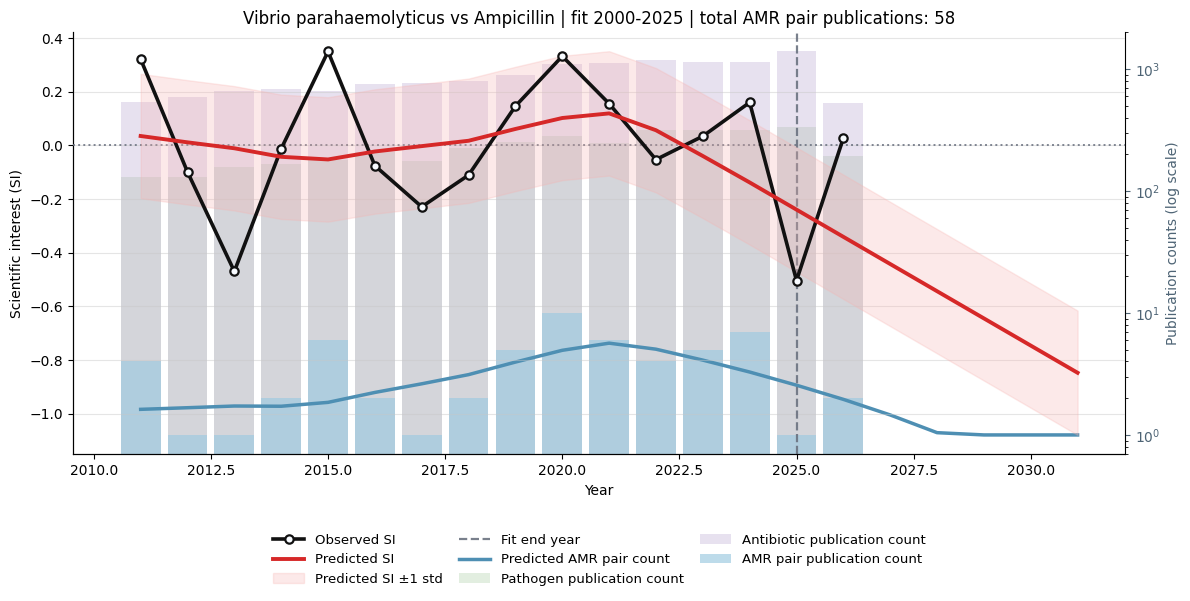

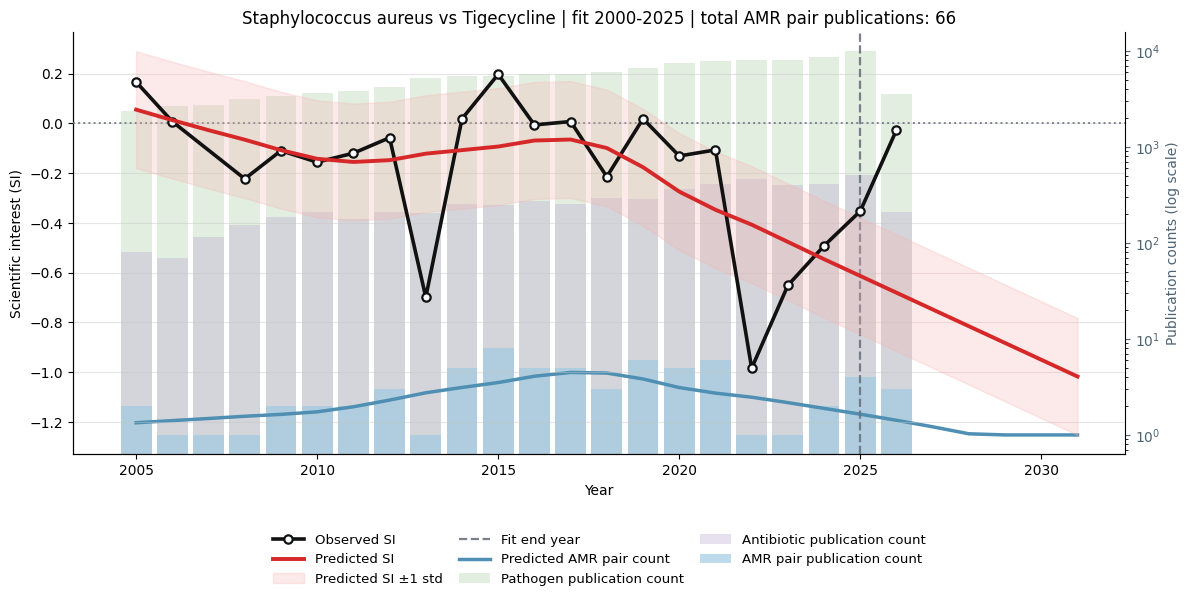

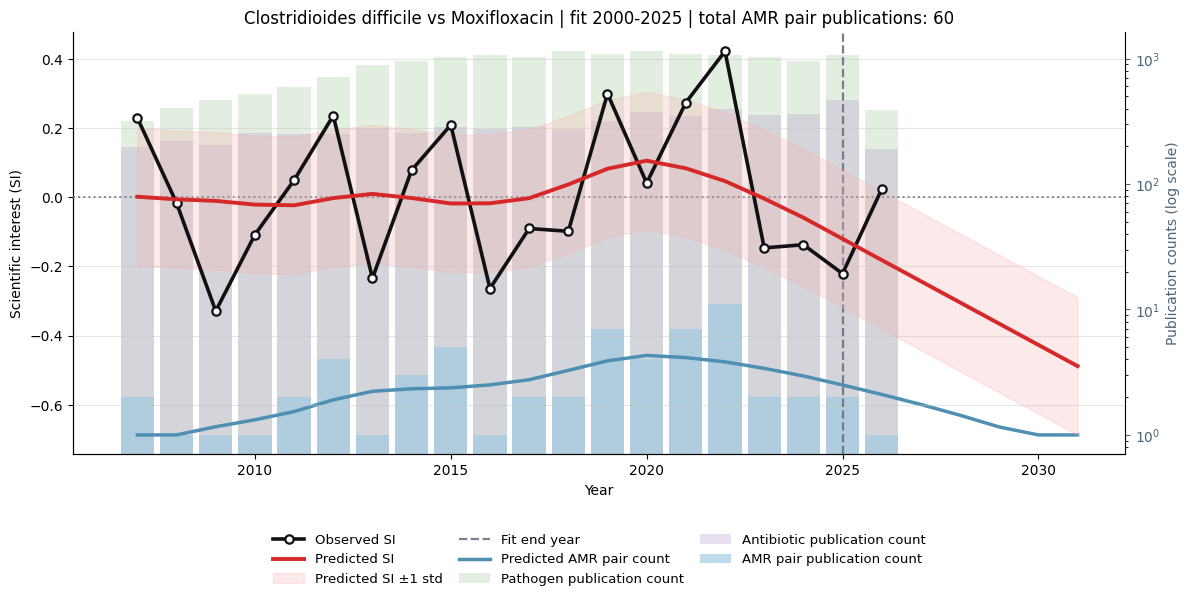

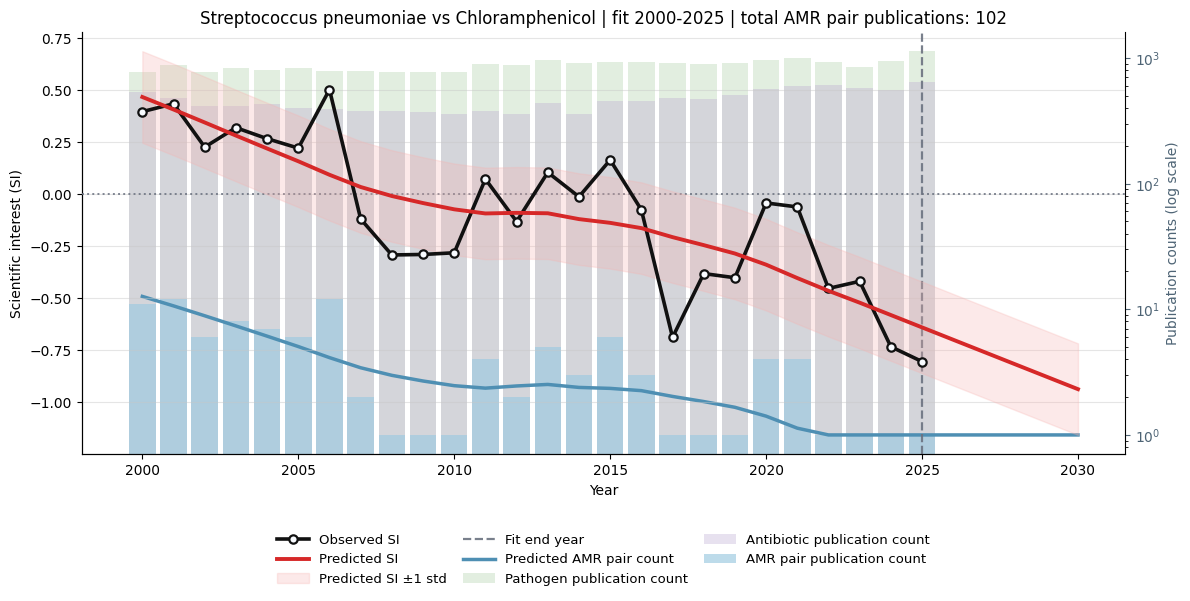

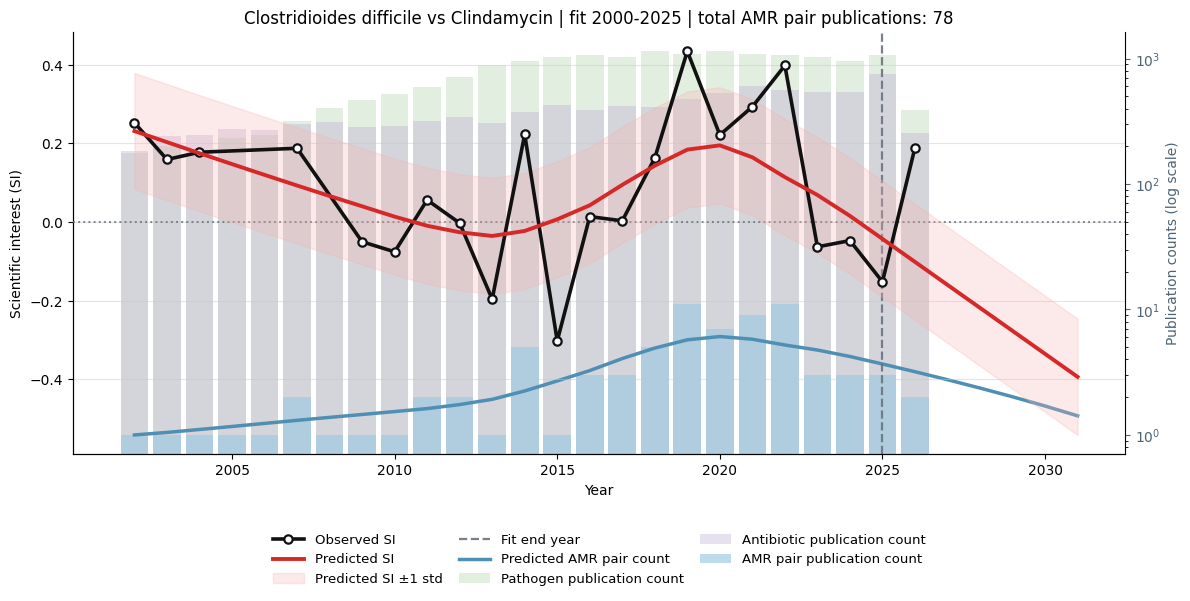

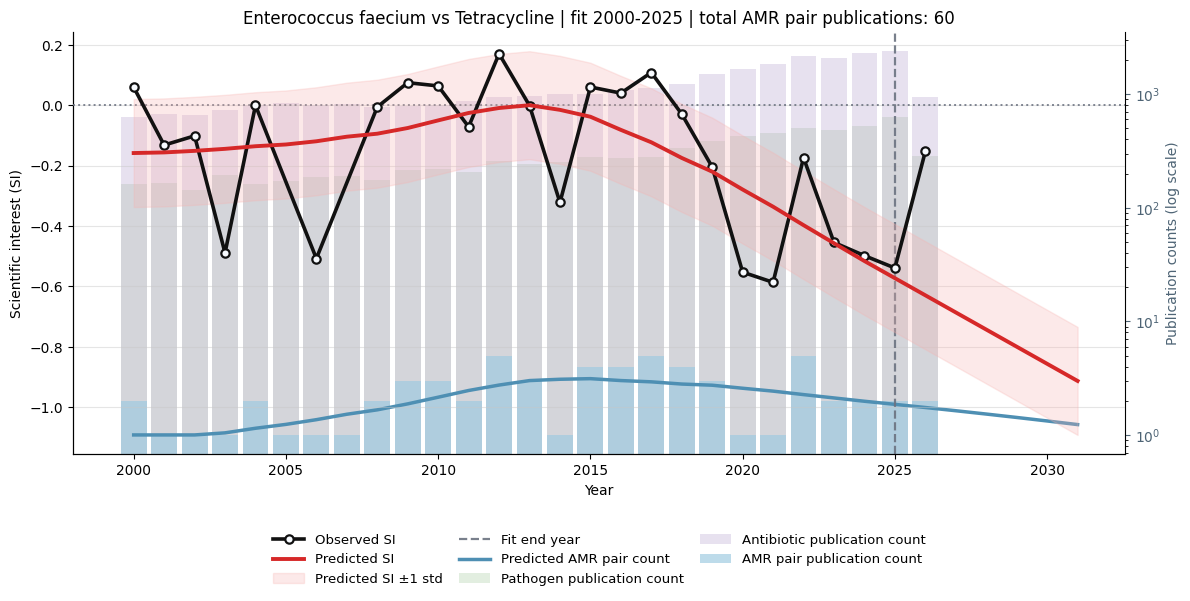

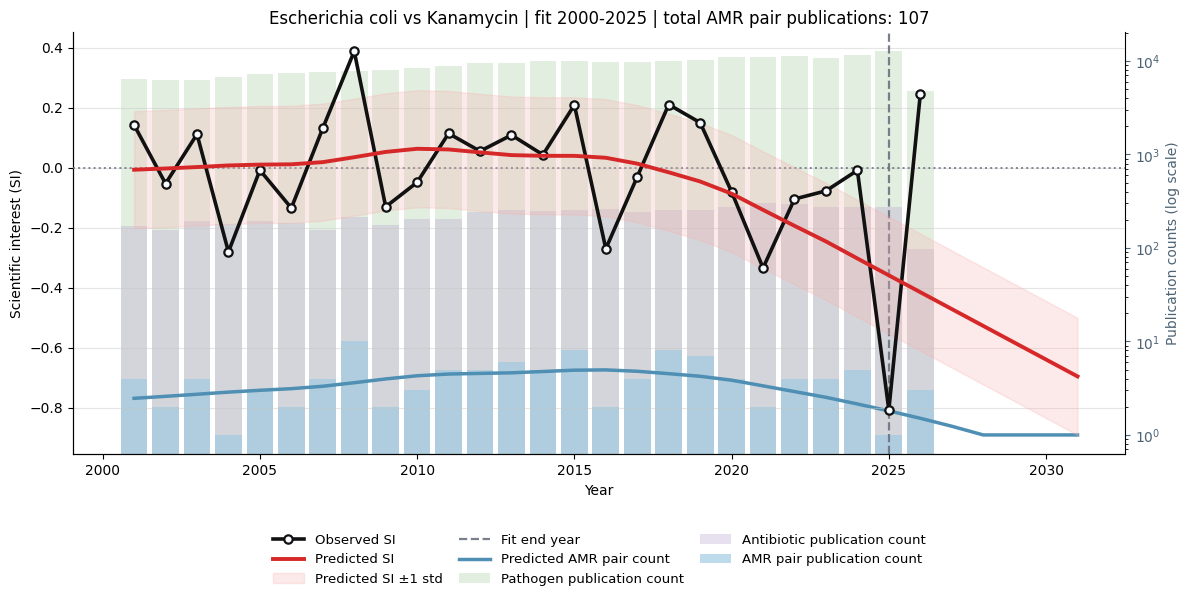

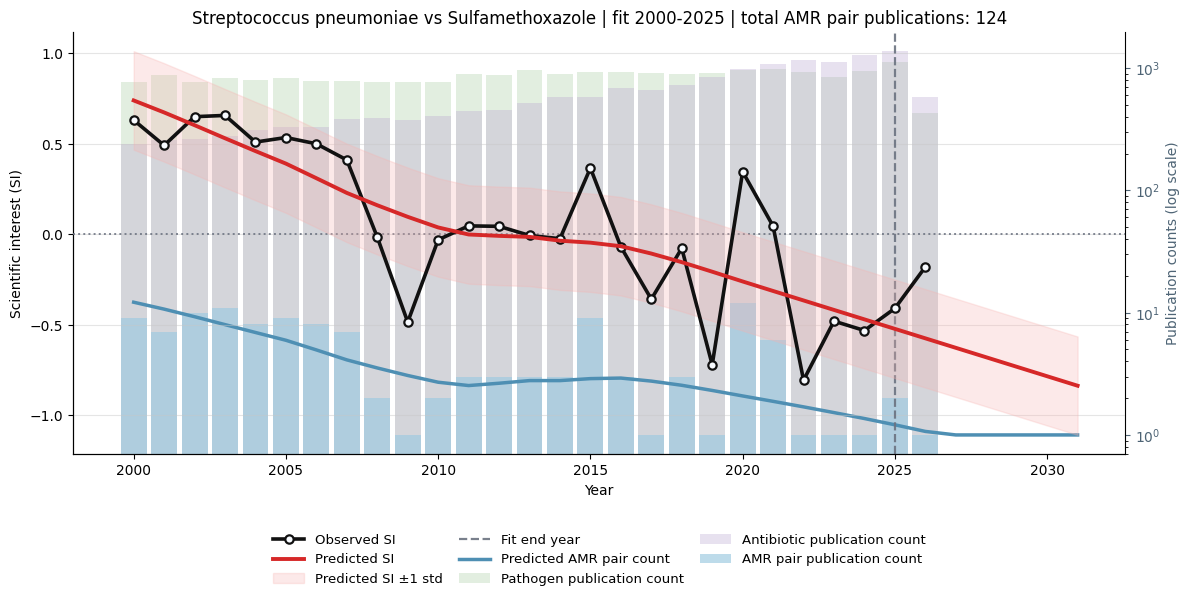

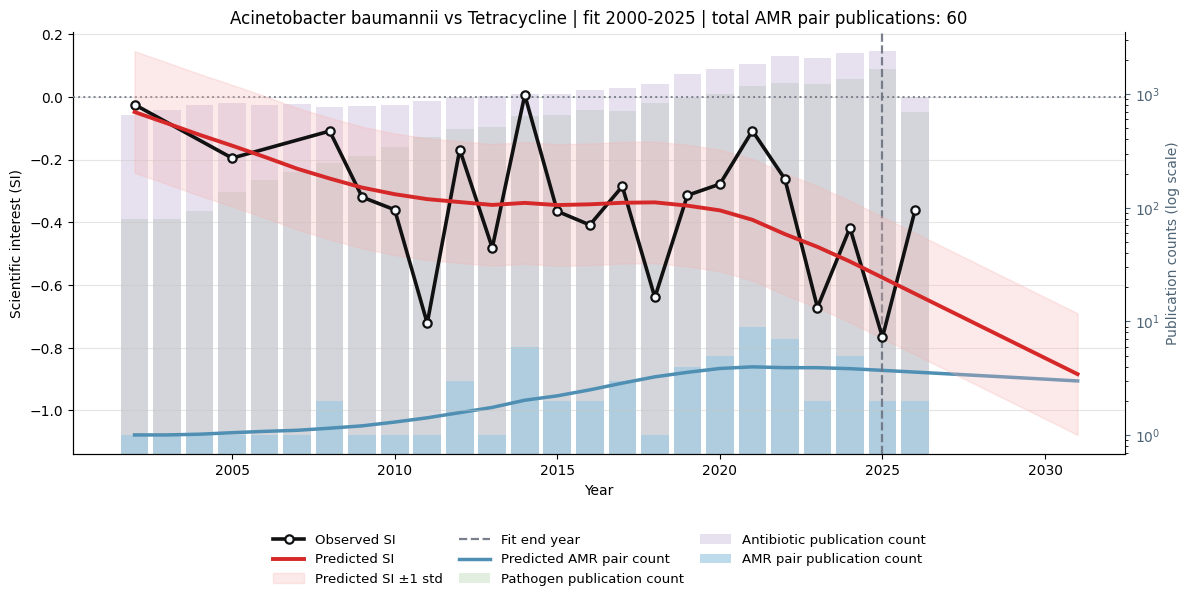

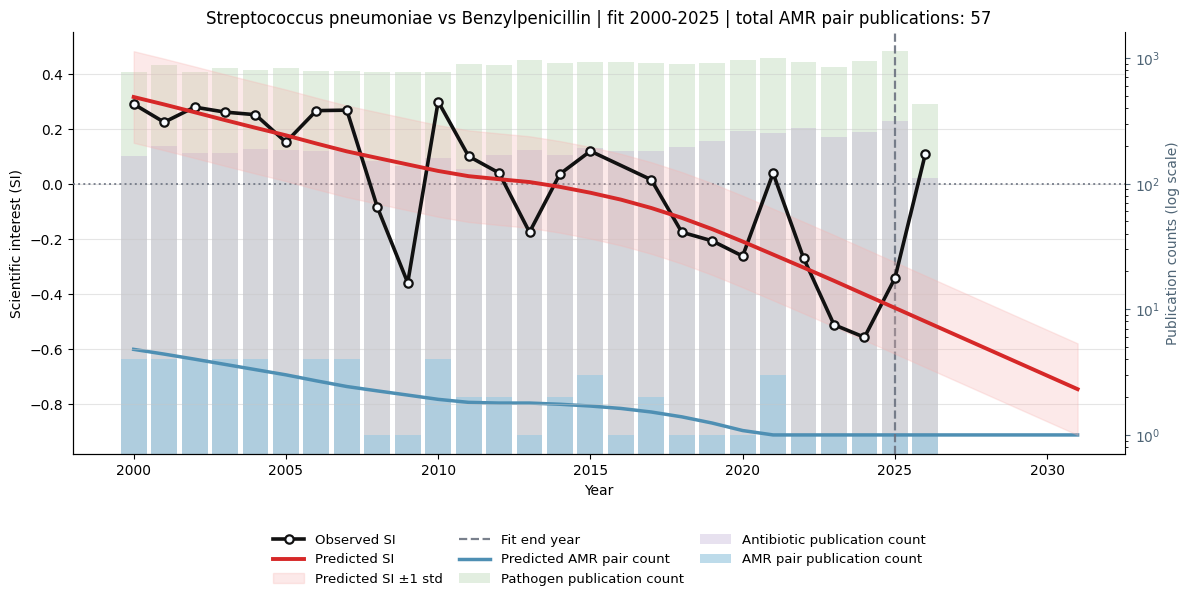

Saved 10 smoothed SI screen plots to /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/decreasing_smoothed_si_plots


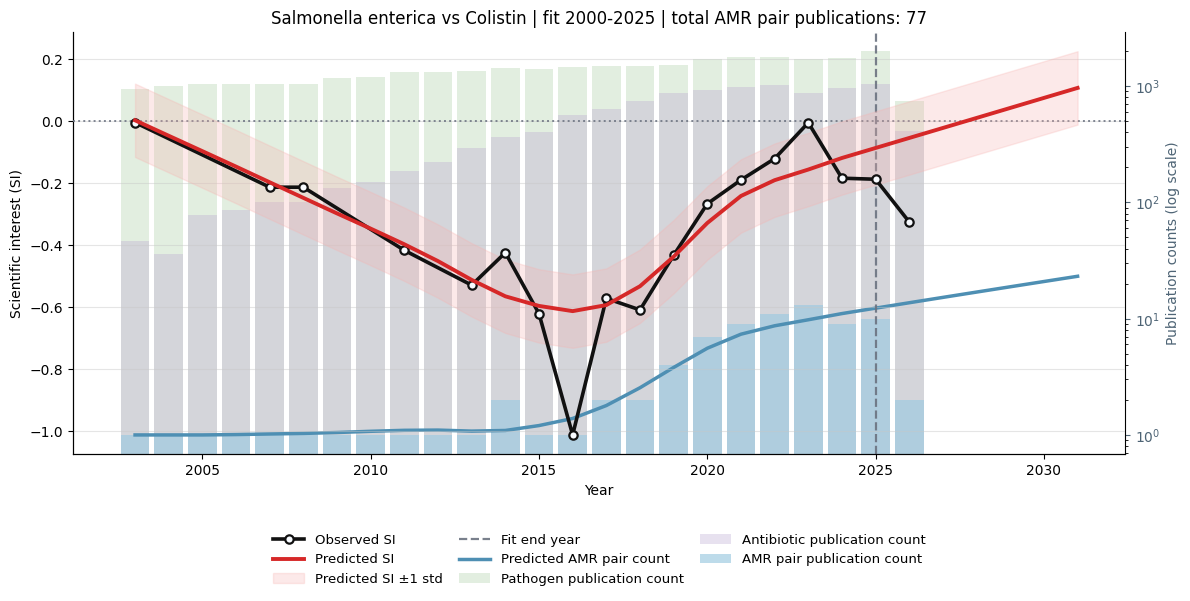

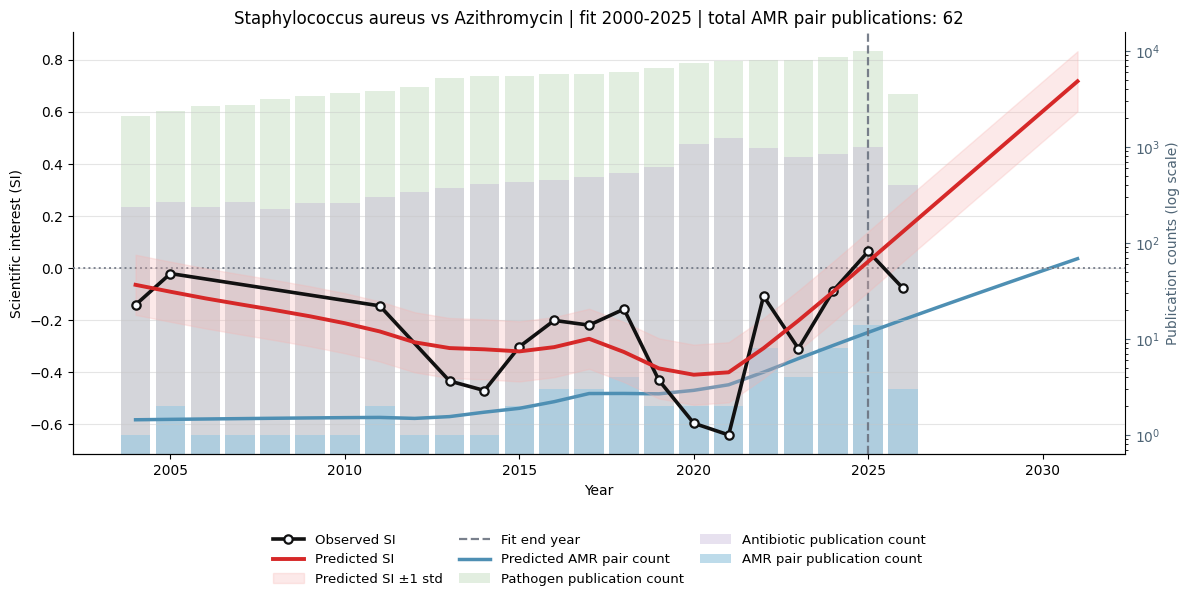

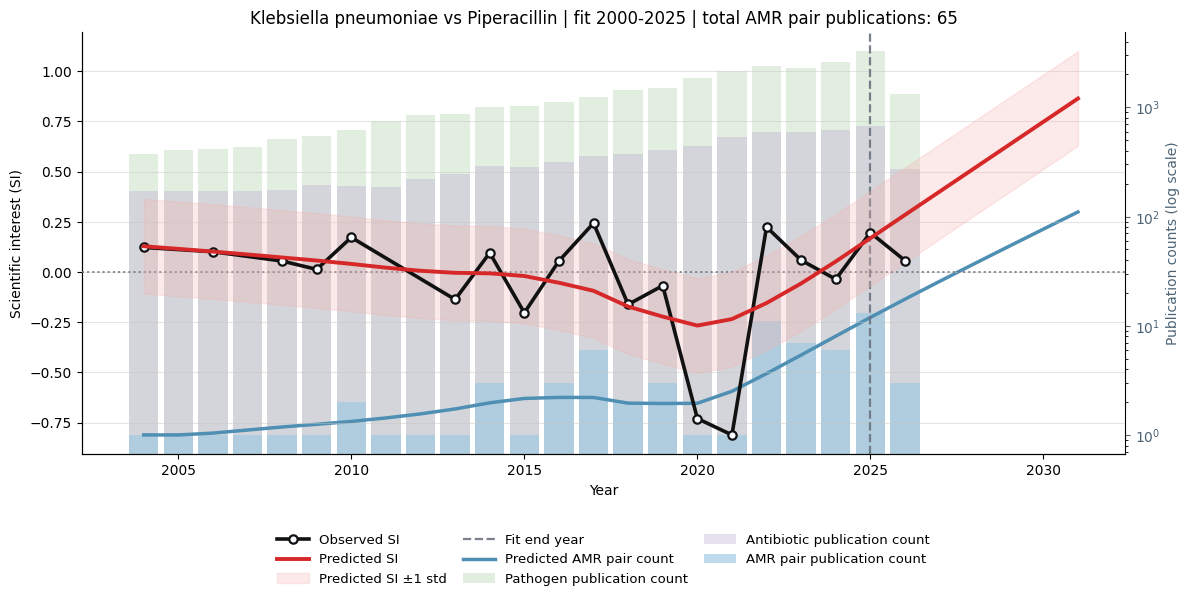

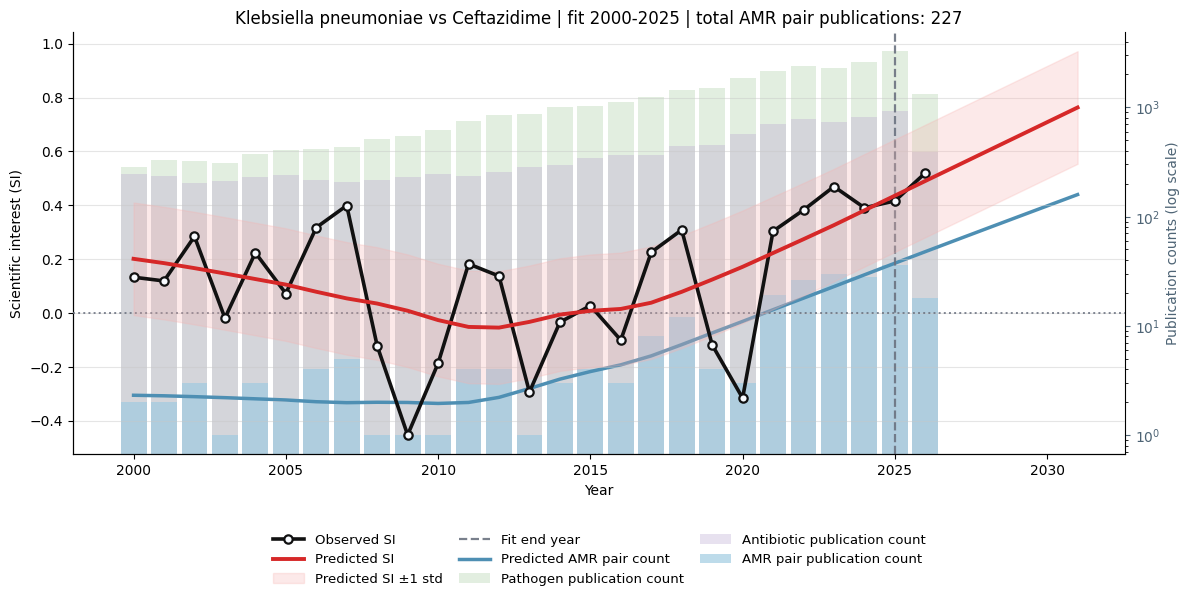

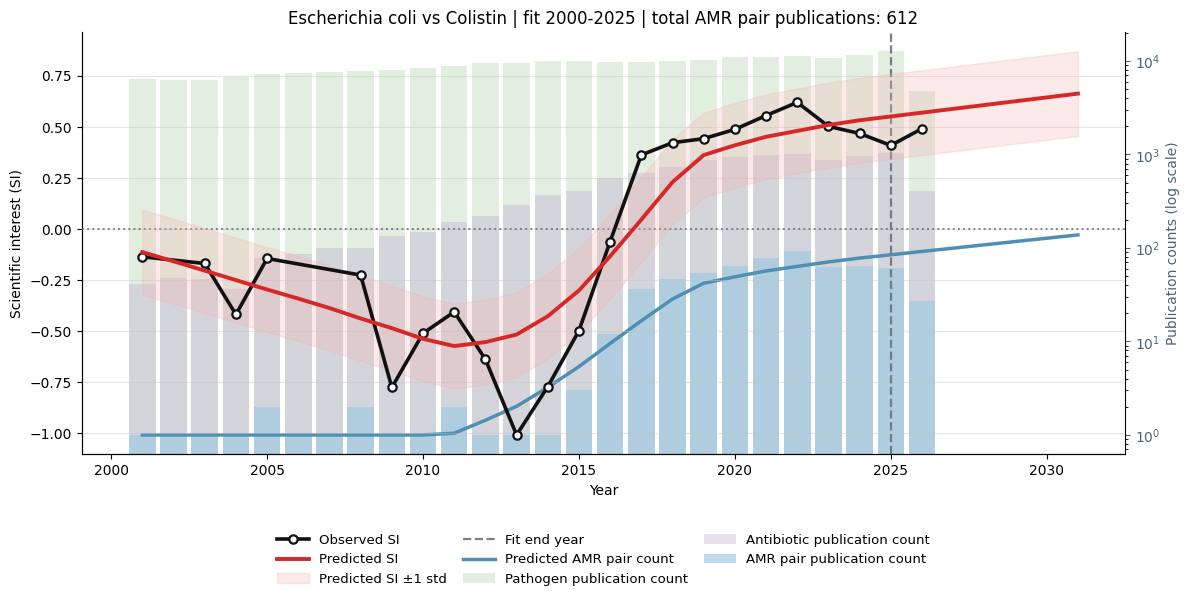

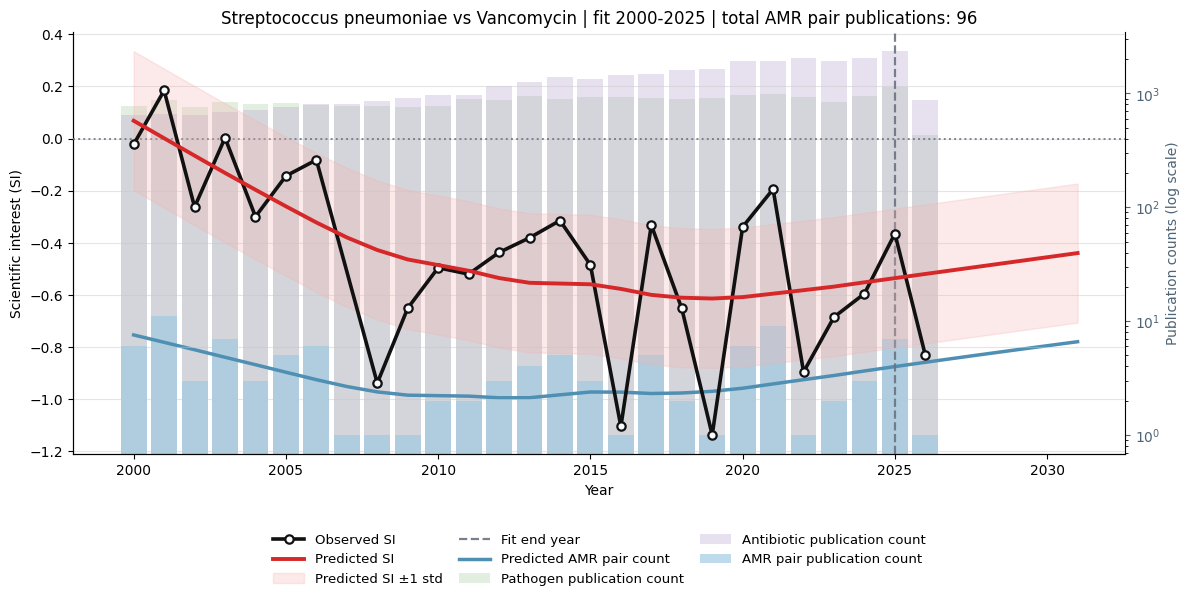

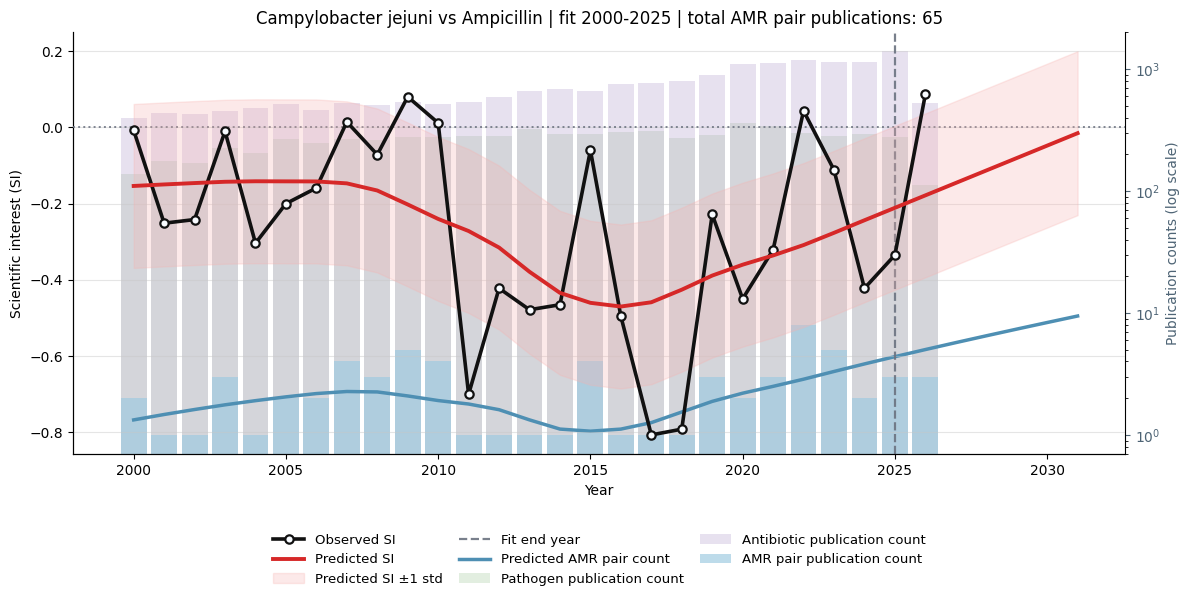

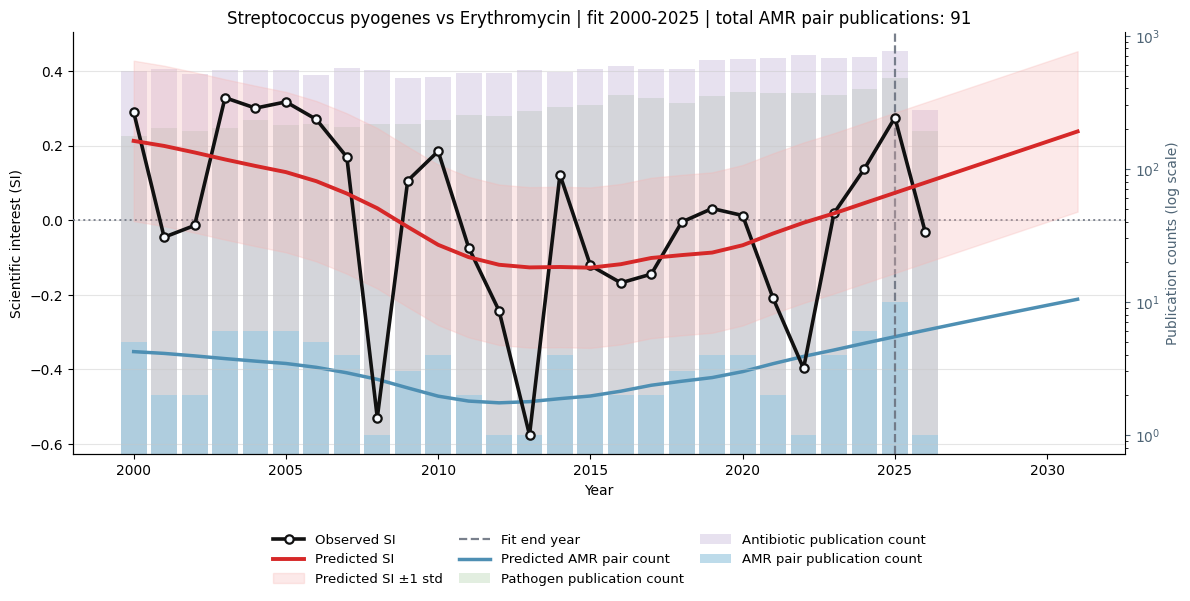

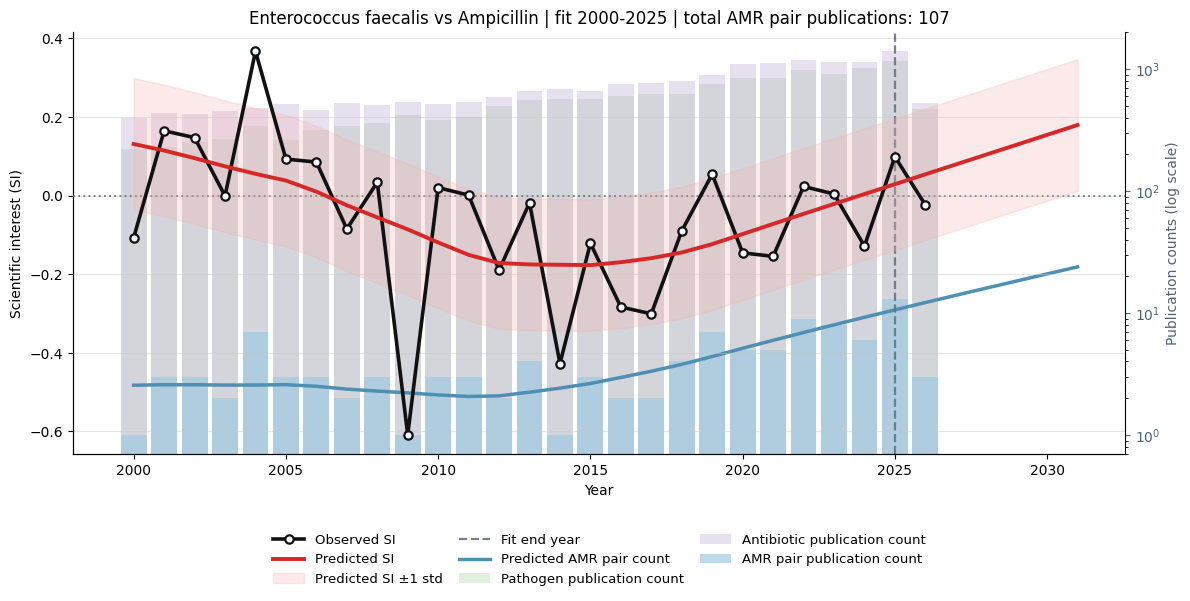

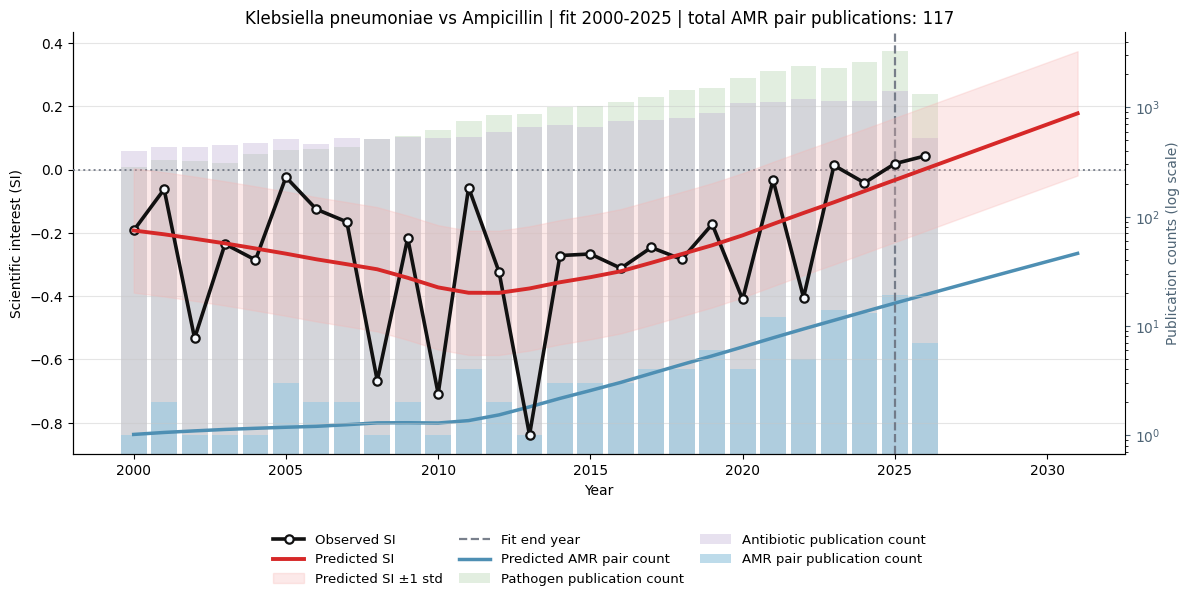

Saved 10 smoothed SI screen plots to /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/convex_u_shaped_smoothed_si_plots


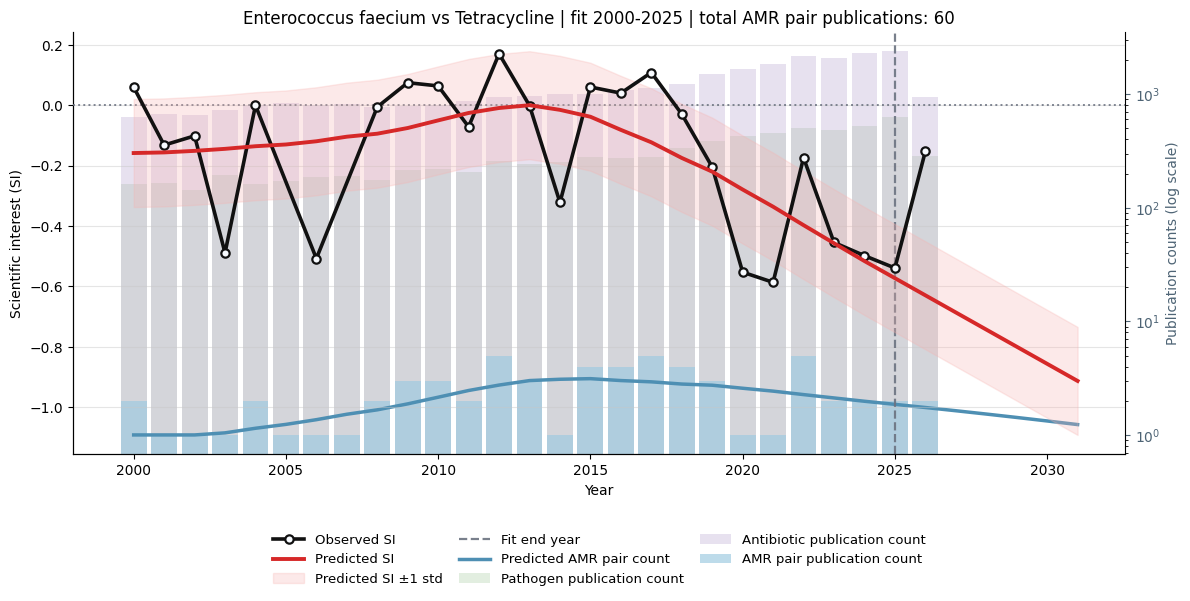

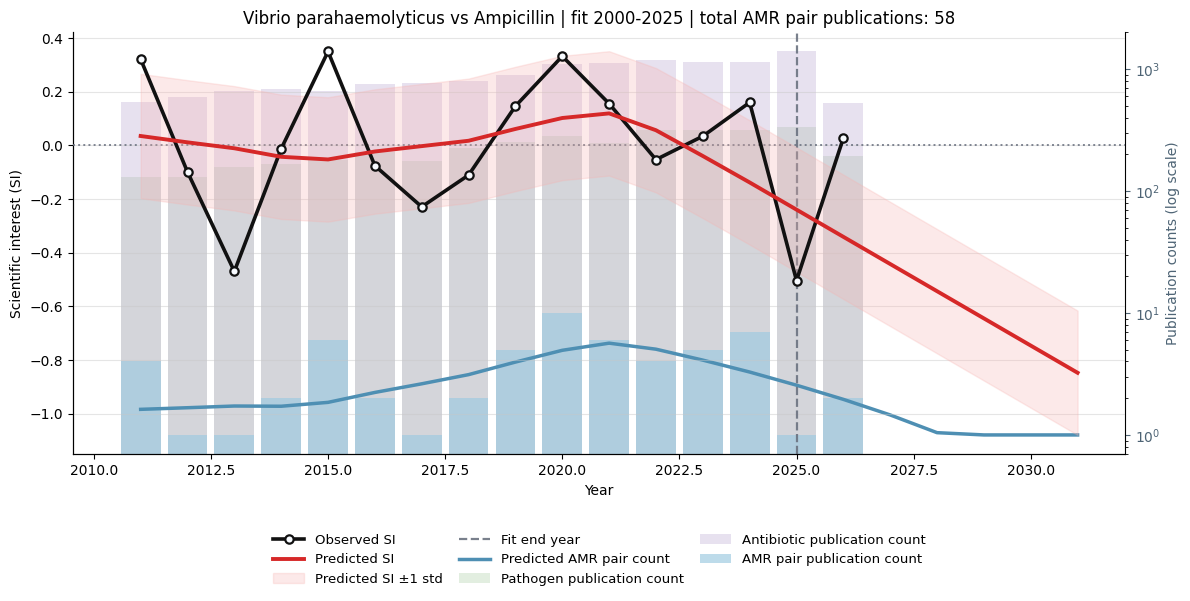

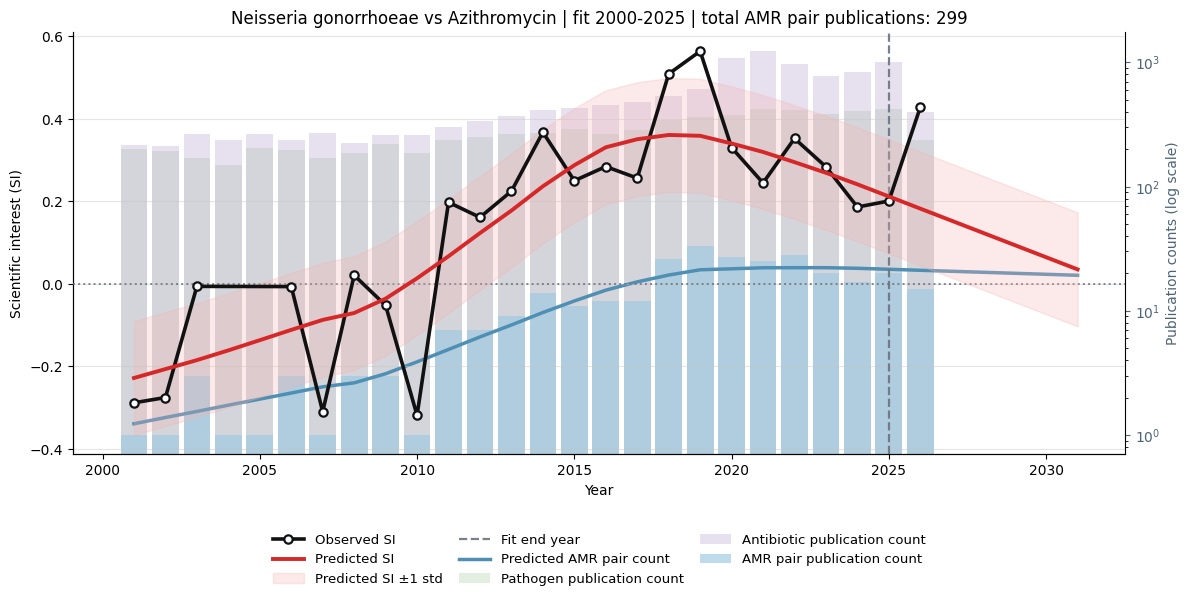

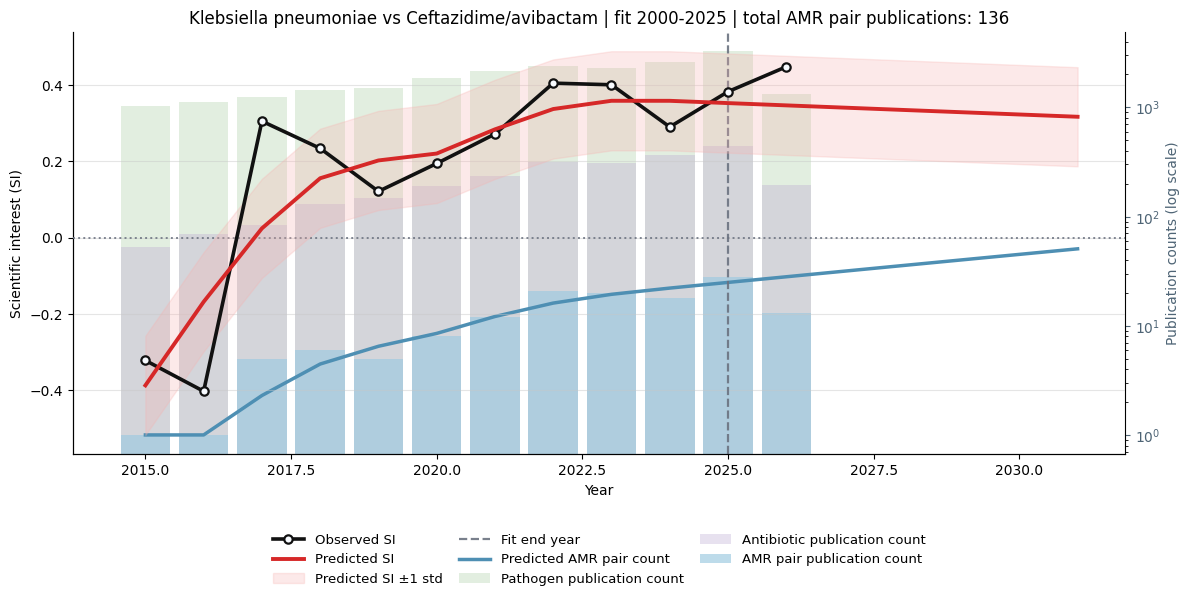

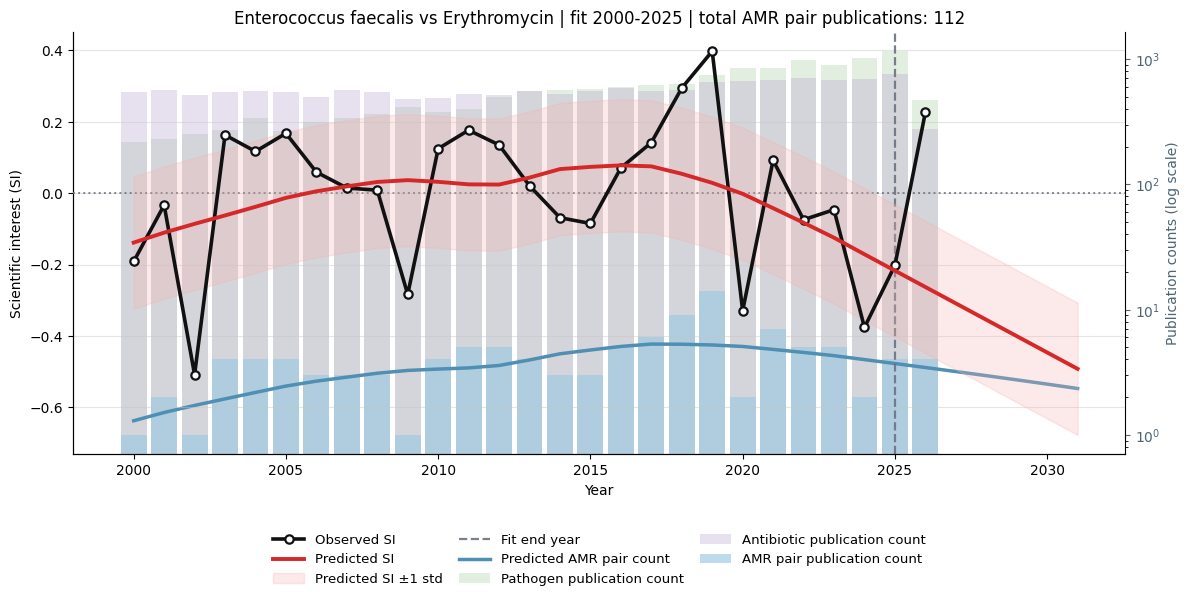

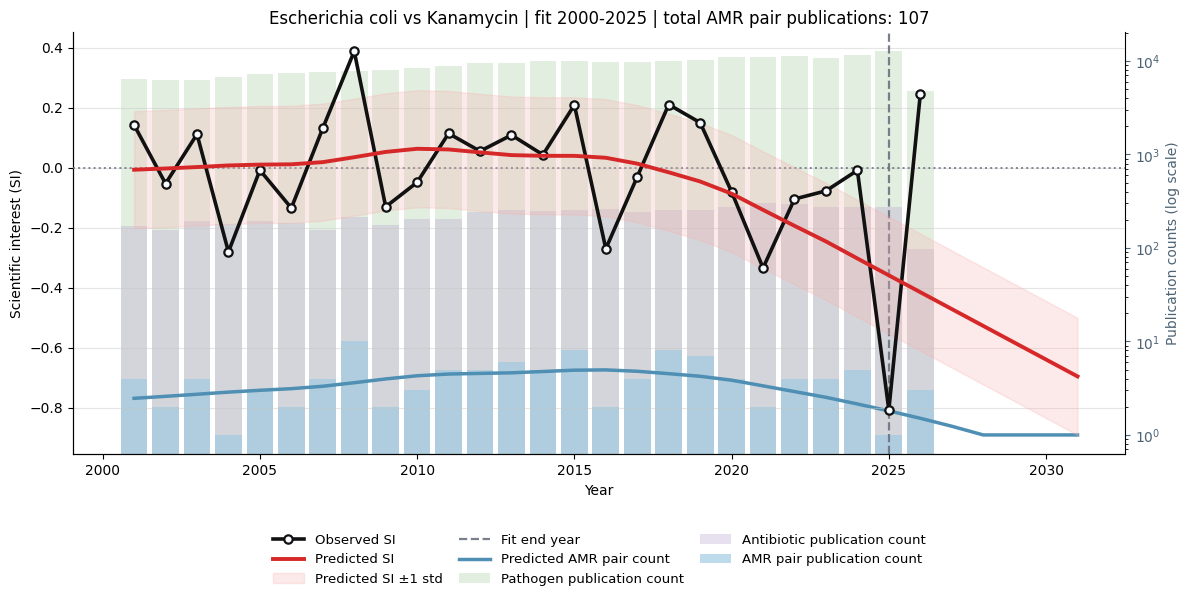

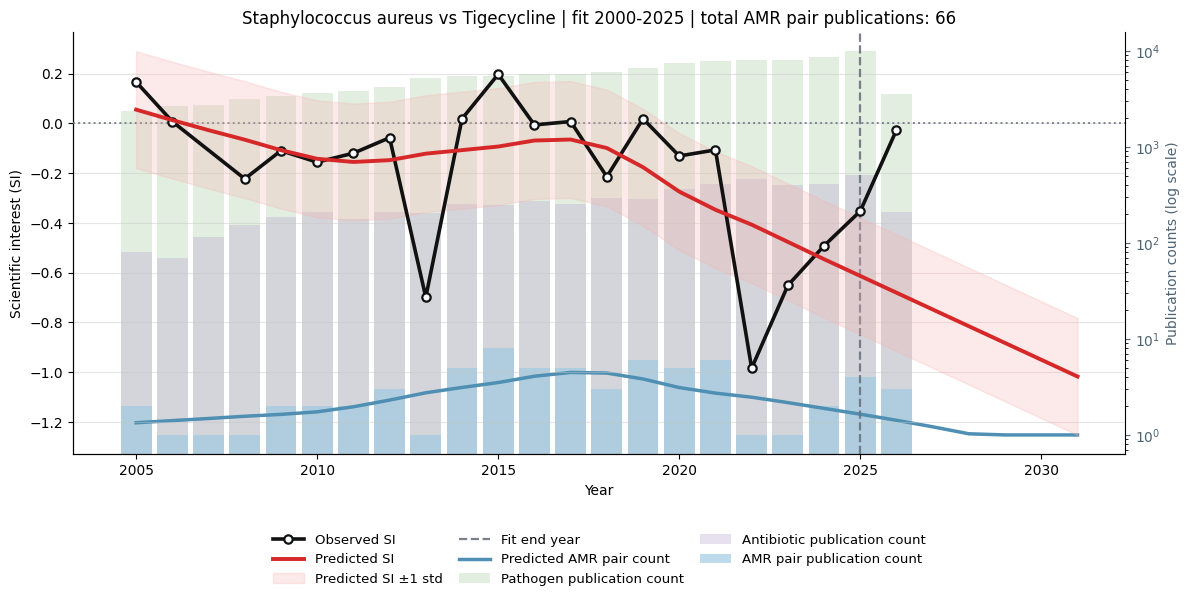

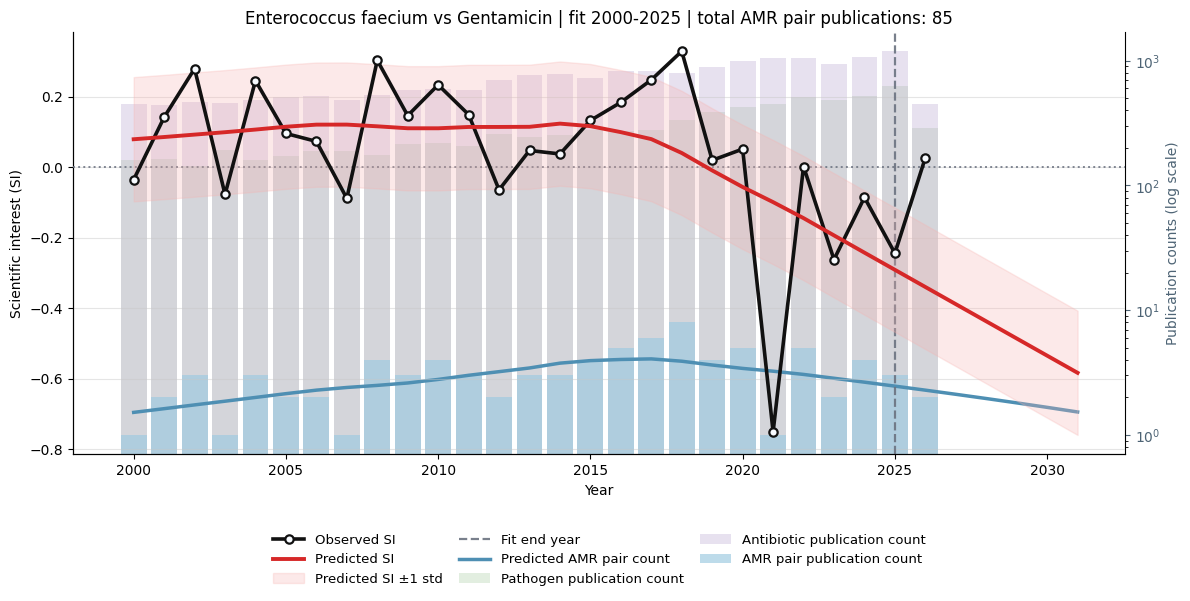

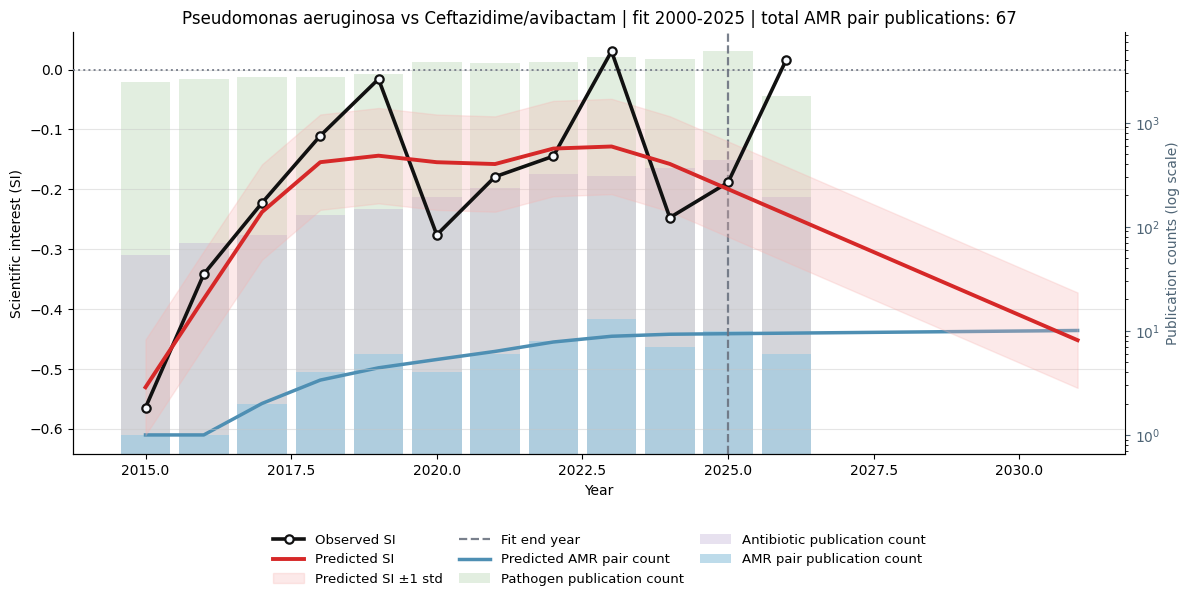

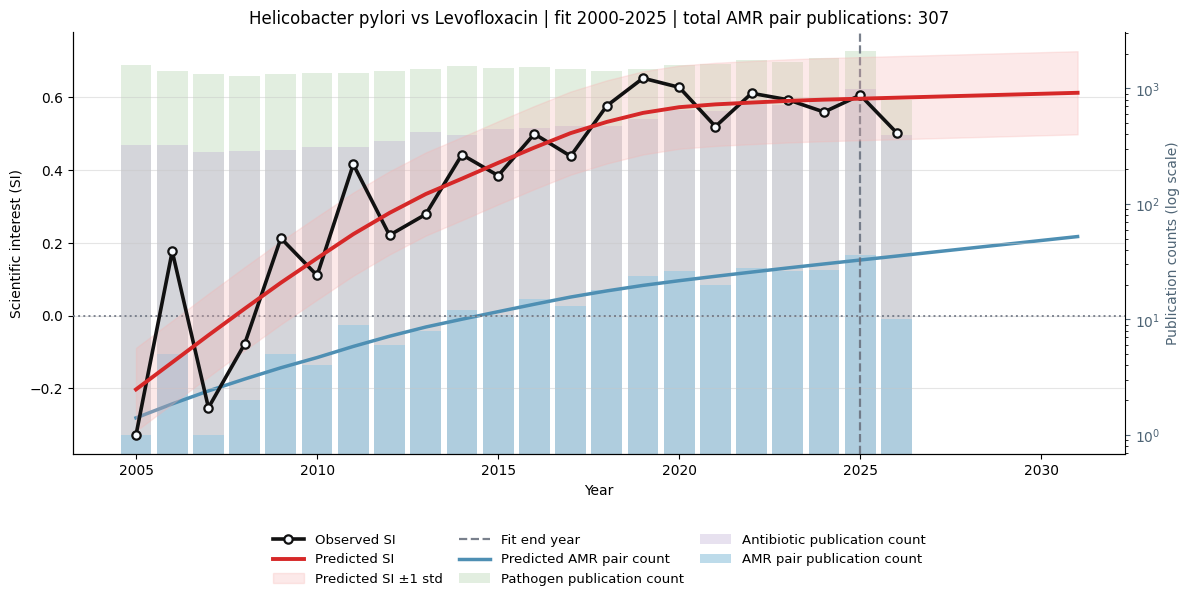

Saved 10 smoothed SI screen plots to /Users/f.costa/Code/Antimicrobial-Resistance/outputs/figures/concave_inverted_u_smoothed_si_plots


10

In [15]:
save_smoothed_si_screen_plots(
    screen_df=decreasing_smoothed_si_df,
    si_df=si_df,
    output_dir=DECREASING_SI_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=SHAPE_SCREEN_PLOT_COUNT,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
)

save_smoothed_si_screen_plots(
    screen_df=most_convex_smoothed_si_df,
    si_df=si_df,
    output_dir=CONVEX_SI_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=SHAPE_SCREEN_PLOT_COUNT,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
)

save_smoothed_si_screen_plots(
    screen_df=most_concave_smoothed_si_df,
    si_df=si_df,
    output_dir=CONCAVE_SI_PLOT_DIR,
    fit_start_year=FIT_START_YEAR,
    curve_fit_end_year=CURVE_FIT_END_YEAR,
    num_future_years=NUM_FUTURE_YEARS,
    pathogen_background_df=pathogen_bg_df,
    antibiotic_background_df=antibiotic_bg_model_df,
    max_plots=SHAPE_SCREEN_PLOT_COUNT,
    figure_format=FIGURE_FORMAT,
    display_plots=DISPLAY_PLOTS,
)
